# 3-servo: friction

Read the drag torque of the servo's motor and train at the motor, both ways, by two routes that share no electrical term, put the static friction on the same scale, and carry the train's efficiency over from the hanging arm. The notebook has no capture of its own. It re-reads the free ladder, the run-ups, the free steps and the hanging arm's lifts, and takes the rest from their results.

## Purpose

Stages 5 to 7 need the drag the motor has to overcome at every speed, as a pair of numbers a firmware can carry, and the friction it has to break before the output moves.

- The Coulomb and viscous terms. The drag's constant part and the part that grows with speed, per direction, in motor units, with brackets.
- Two routes. The winding current at a steady speed times Kt, and the inertia times the free coast's deceleration. The first leans on the current's zero and its crest term, the second on the inertia, so their agreement tests both.
- The train's share. The servo's drag less the bare motor's, from the type's stage 2 motors.
- The static friction. What holds a still rotor against the motor and a still output against gravity, on the same scale as the running drag.
- The efficiency. Kt through the gears against the lossless value at a stall, at speed while lifting, and back-driven while falling.

## Procedure

The procedure is the README's `friction` section. No sitting ran for it. The ladder, run-up and steps sittings ran with the horn free, and the load sitting `servo-load-1` with the printed arm hanging from the horn, all on the experiment image, so every drive is open loop.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The free ladder is `ladder/capture-1` and `ladder/rail-1` (`cycles.csv`, a spin and a coast with the bridge open per cycle, both directions, on the three rails) and its low holds `ladder/low-1`. The run-ups are the six `run-up/runup-open-N` and `runup-close-N` sets, 5 V spins at full duty from rest, each with a coast. The free steps are `steps/capture-1` (`chains.csv`). The hanging arm's lifts and falls are `load/lift-1` (`cycles.csv`). The sitting manifests under `sittings/` give the rail and the board NTC before each sweep. Each sweep folder holds `sweep.csv`, one row per control tick, and `meta.json`, whose sense block is checked against the board's registry entry on load.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter

from oscnb import (boards, coast, cycles, figures, motors, results, ripple,
                   scales, servos, tel)
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, limits
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
FS = BOARD.tick_hz                      # rows per second, the control tick
ARR = BOARD.pwm_arr                     # timer ticks per PWM period
GEAR = SERVO.gear_ratio                 # motor revs per output rev, teeth
PER_REV = MOTOR.ripple_per_rev          # commutation events per motor rev
RPS = 2 * np.pi                         # rad/s per rev/s
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR))
print(f"gear {GEAR:.4f}:1, {PER_REV} ripple events per motor rev, {FS} "
      f"rows/s, PWM period {ARR} ticks")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
gear 308.0533:1, 6 ripple events per motor rev, 20000 rows/s, PWM period 1200 ticks


## 1. The setup

### Earlier results carried in

The stage 1 scales turn counts into amps and volts, with the bridge's edge lags on each rail. The ladder gives Ke, which in SI units is also Kt. The resistance result gives construction C, the way this servo's partial-duty current and volts are read, with its line's R and V0 and the crest term g the meter confirmed. Bridge-states gives the brake loop, run-up the inertia J of the rotor and the train at the motor, the free steps the play at a start, the pot table the lash and its counts-to-degrees table, and the load result every torque the hanging arm gives, absolute with the arm weighed. Stage 2's no-load-current results on mg90-b and mg90-c stand as the type's bare motor, a comparison only.

In [3]:
SC = scales.load(BOARD)                 # stage 1: counts to amps and volts
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD.key)
LADDER = results.read("3-servo", "ladder", pair=PAIR)
RUNUP = results.read("3-servo", "run-up", pair=PAIR)
FREE_STEPS = results.read("3-servo", "steps", pair=PAIR)
RES = results.read("3-servo", "resistance", pair=PAIR)
POT = results.read("3-servo", "pot-table", pair=PAIR)
LOAD = results.read("3-servo", "load", pair=PAIR)
# the type's bare motors from stage 2, a comparison column only
TYPE_NL = {m: results.read("2-motor", "no-load-current", pair=m)
           for m in ("mg90-b", "mg90-c")}
SC.describe()

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end


In [4]:
KE = LADDER["ke_v_s_per_rad"]["value"]       # V s/rad, = Kt in N m/A
KE_HI = LADDER["ke_v_s_per_rad"]["hi"]       # its upper bound
KT = KE                                      # SI: the same constant
R_C = RES["r_rails_c_ohm"]["value"]          # ohm, construction C's line
V0_C = RES["v0_rails_c_v"]["value"]          # V, that line's offset
G_S = RES["meter_g_ms"]["value"] / 1e3       # S, the crest term, meter
G_S_HI = RES["meter_g_ms"]["hi"] / 1e3       # S, its upper bound
EDGE_5V = RES["edge_ticks_measured_5v"]["value"]   # ticks, edges at 5 V
R_BRAKE = BRIDGE["low_side_loop_ohm"]["value"]     # ohm, the brake loop
J = RUNUP["j_kg_m2"]["value"]                # kg m2, rotor + train
J_LO, J_HI = RUNUP["j_kg_m2"]["lo"], RUNUP["j_kg_m2"]["hi"]
OFFSET = SC.drive_offset_counts              # counts, stage 1 in-drive
COUNTS_PER_TURN = SERVO.counts_per_motor_rev   # pot counts per motor rev
print(f"Ke = Kt {KE * 1e3:.4f} mV s/rad (to {KE_HI * 1e3:.4f}); "
      f"construction C {R_C:.3f} ohm, V0 {V0_C * 1e3:+.0f} mV")
print(f"g {G_S * 1e3:.2f} mS (to {G_S_HI * 1e3:.2f}), edges {EDGE_5V:.2f}"
      f" ticks at 5 V, brake loop {R_BRAKE:.3f} ohm")
print(f"J {J * 1e9:.2f}e-9 kg m2 ({J_LO * 1e9:.2f} to {J_HI * 1e9:.2f}); "
      f"in-drive offset {OFFSET:+.2f} counts; pot "
      f"{COUNTS_PER_TURN:.2f} counts per motor turn (nominal)")
for rail in (3.7, 5.0, 7.4):
    on, off, _, _ = SC.edge_lags_at(rail)   # stage 1's lags on the rail
    print(f"  edge lags at {rail} V: ON - OFF {on - off:.2f} ticks")

Ke = Kt 1.1591 mV s/rad (to 1.1664); construction C 4.177 ohm, V0 +31 mV
g 4.75 mS (to 4.97), edges 25.05 ticks at 5 V, brake loop 0.301 ohm
J 6.43e-9 kg m2 (5.86 to 7.07); in-drive offset +5.26 counts; pot 23.14 counts per motor turn (nominal)
  edge lags at 3.7 V: ON - OFF 24.00 ticks
  edge lags at 5.0 V: ON - OFF 25.05 ticks
  edge lags at 7.4 V: ON - OFF 27.00 ticks


### The drag model and the units

The drag torque at the motor is taken as

$$T = T_c\,\mathrm{sgn}(\omega) + b\,\omega$$

with $T$ the drag torque, $T_c$ the Coulomb term, a constant drag that only changes sign with the direction of turning, $b$ the viscous term, the drag per unit of speed, and $\omega$ ("omega") the motor's speed in rad/s. In the code and the tables they are Tc, b and w. Every torque here is at the motor in uN m and the viscous term in uN m s/rad. Each is also written as the current that makes it through Kt, in mA at Ke, with Ke = Kt at 1.1591 mV s/rad. Output torques stay in mN m.

Three routes reach the drag.

- Route 1, the ladder. At a steady speed the motor's torque equals the drag, so Kt times the winding current is the drag torque. Only the current-side terms matter there, the current's zero and the crest term g (1 - D) V_on, with D the duty and V_on the crest tap volts. R, V0 and the brush drop sit in the volts balance and are reported only as its residual.
- Route 2, the coasts. With the bridge open nothing electrical acts, so J times the coast's deceleration is the drag. It carries J's bracket and no current term.
- Route 3, the hanging arm. Gravity is a known torque at the output, and the load result's holds, falls and stall lines carry the friction and the train's efficiency there.

### The hanging arm's torques

The load result made gravity's torque absolute with the arm weighed. The factor, the masses and the bottom come from it here.

In [5]:
SCALE = LOAD["gravity_torque_scale"]["value"]    # absolute / coins-scale
TAU_COINS = LOAD["tau_coins_horizontal_mn_m"]["value"]   # mN m, coins
TAU_H = LOAD["tau_horizontal_mn_m"]["value"]     # mN m, coins + the arm
BOTTOM = int(LOAD["bottom_counts"]["value"])     # counts, of record
HELD = LOAD["static_friction_held_lower_mn_m"]   # mN m, a lower bound
RELEASE = LOAD["static_friction_release_mn_m"]   # mN m, mean +/- sd
KT_GEAR = LOAD["kt_gear_mn_m_per_a"]             # mN m/A, absolute
INTERCEPT = LOAD["torque_line_intercept_mn_m"]   # mN m, the lines' T0
# sittings 2 and 3: the back-driven hold measured, and the duty deadband
STATIC = LOAD["static_friction_mn_m"]            # mN m at the output
STATIC_UNM = LOAD["static_friction_un_m_motor"]  # uN m at the motor
STATIC_BAR = tuple(STATIC_UNM[k] for k in ("value", "lo", "hi"))
STATIC_HELD = LOAD["static_friction_held_mn_m"]  # mN m, the most held
STATIC_FREE = LOAD["static_friction_released_mn_m"]   # mN m, least freed
DEADBAND = {"up": LOAD["hold_deadband_up_duty_pct"],      # % of duty
            "down": LOAD["hold_deadband_down_duty_pct"]}
print(f"coins {LOAD['coins_mass_g']['value']:.2f} g at "
      f"{LOAD['coins_radius_mm']['value']:.2f} mm; block + lid + screws "
      f"{LOAD['coin_block_g']['value']:.1f} g at "
      f"{LOAD['coin_block_radius_mm']['value']:.1f} mm; mount "
      f"{LOAD['arm_mount_g']['value']:.1f} g at "
      f"{LOAD['arm_mount_radius_mm']['value']:.1f} mm")
print(f"gravity at horizontal {TAU_COINS:.2f} coins + "
      f"{TAU_H - TAU_COINS:.2f} arm = {TAU_H:.2f} mN m, factor "
      f"{SCALE:.4f}; bottom {BOTTOM} counts")

coins 124.74 g at 68.43 mm; block + lid + screws 28.3 g at 55.0 mm; mount 13.0 g at 14.1 mm
gravity at horizontal 83.71 coins + 17.04 arm = 100.75 mN m, factor 1.2035; bottom 2021 counts


The coins give 83.71 mN m at horizontal and the arm 17.04, 100.75 mN m in all, the factor 1.2035 on every coins-scale torque. The bottom of record is 2021 counts, the load notebook's. Every output torque below is absolute.

In [6]:
def u_nm(torque_n_m):
    """N m to uN m, the motor-side unit."""
    return torque_n_m * 1e6


def ma_at_kt(torque_n_m):
    """A torque at the motor as the current that makes it through Kt, mA."""
    return torque_n_m / KT * 1e3

### The sitting manifests

The runner read the pot, the board NTC and the rail before every sweep. A sweep's rail is its probe's, not the set level.

In [7]:
PATTERN = r"(.+?): pos (\d+), ntc_raw (\d+), vbus_raw (\d+)"
rows = []
for p in sorted((PAIR_DIR / "sittings").glob("servo*.csv")):
    ev = pd.read_csv(p)
    x = ev[ev["event"] == "probe"]["detail"].str.extract(PATTERN).dropna()
    rows.append(pd.DataFrame({"label": x[0], "pos": x[1].astype(int),
                              "ntc_raw": x[2].astype(int),
                              "vbus_raw": x[3].astype(int)}))
PROBES = pd.concat(rows, ignore_index=True)
PROBES["ntc_c"] = BOARD.ntc_c_beta(PROBES["ntc_raw"])
PROBES["rail_v"] = SC.rail_v(PROBES["vbus_raw"])
PROBES["folder"] = PROBES["label"].str.replace(f"telemetry/{PAIR}/", "",
                                               regex=False)
# a folder probed twice keeps its last probe, the one before its sweep
PROBES = PROBES.drop_duplicates("folder", keep="last").set_index("folder")


def probe_for(folder):
    """The manifest's probe before a sweep's folder, None without one."""
    rel = str(Path(folder).resolve().relative_to(PAIR_DIR))
    return PROBES.loc[rel] if rel in PROBES.index else None


print(f"{len(PROBES)} probed sweeps over the sitting manifests")

548 probed sweeps over the sitting manifests


## 2. Reading the ladder again

Every spin is re-read from its raw sweep, with the window and the gates below.

In [8]:
WINDOW_MS, WINDOW_MIN_MS = 100, 20      # ms, the spin window's span
AWAKE_MS = 100                          # ms, the coast tail's awake zero
SETTLE_PCT = 2.5                        # %, the ladder's settled gate
NEAR_PCT = 7.0                          # %, tier 2's settle
LADDER_SETS = ("capture-1", "rail-1")   # the free ladder's two blocks
print(f"spin window the held duty's last {WINDOW_MS} ms, at most half the "
      f"held rows, at least {WINDOW_MIN_MS} ms; awake zero the coast's last "
      f"{AWAKE_MS} ms; tiers at {SETTLE_PCT} and {NEAR_PCT} % of settle")

spin window the held duty's last 100 ms, at most half the held rows, at least 20 ms; awake zero the coast's last 100 ms; tiers at 2.5 and 7.0 % of settle


The window is the held duty's last 100 ms, at most half the held rows and at least 20 ms. The crest current is read over the sweep's own torque-off zero with the stage 1 in-drive offset taken out, and over the sweep's awake zero, the coast tail's current, as the variant. The ripple tach, the count of the current's commutation ripple, gives the speed over the window, seeded by the coast's EMF line and checked against the pot. The window before it gives the settle, how much the speed still grew. The coast's early EMF after the taps settle gives its deceleration at the cut. Construction C runs at each sweep's own rail, the edge lags from stage 1 at that rail, the brake loop's drop between windows and g off the current.

In [9]:
def load_sweep(folder):
    """(rows, current zero, tap zero): the sense block checked on load,
    the zeros the sweep's own torque-off baseline."""
    df, _ = tel.load(folder, board=BOARD)
    zero_i, zero_e = tel.rest_zeros(df)
    return df, zero_i, zero_e


def crest_amps(raw, zero_i, offset):
    """Crest current in A over the zero, `offset` counts taken out."""
    return (np.asarray(raw, float) - zero_i - offset) / SC.counts_per_a


def construction_c(half_ticks, rail_v, v_on, i_crest, g=G_S):
    """(share, winding current, applied volts) under construction C at
    this rail: stage 1's edge lags off the window, the brake loop's drop
    between windows and the crest term g (1 - D) V_on off the current."""
    D = np.asarray(half_ticks, float) / ARR
    share, s_lo, s_hi = SC.share_of(half_ticks, rail_v, 2 * ARR)
    c = scales.constructions(D, share, v_on, i_crest, s_lo, s_hi,
                             R_BRAKE, g)
    return share, c["i_c"], c["v_c"]


def pot_slope_rev_s(pos):
    """Motor rev/s from a line through the pot, nominal counts per turn."""
    p = np.asarray(pos, float)
    t = np.arange(len(p)) / FS
    return float(np.polyfit(t, p, 1)[0] / COUNTS_PER_TURN)

In [10]:
def tach_rev_s(current, f_seed, passes=6, frac=ripple.BAND_FRAC):
    """(rev/s, cycles): the ripple tach over the whole cycles of
    `current`, the band re-centered on each count until it converges;
    nan when the seed is out of band or the count fails."""
    x = np.asarray(current, float)
    f, n = f_seed, 0
    for _ in range(passes):
        top = ripple.NYQUIST_SHARE * FS / 2   # the band's highest edge
        if not np.isfinite(f) or f <= 0 or f * (1 + frac) >= top:
            return np.nan, 0
        f_new, n = ripple.count_cycles(x, f, frac)
        if not np.isfinite(f_new):
            return np.nan, 0
        done = abs(f_new / f - 1) < ripple.CONVERGED
        f = f_new
        if done:
            break
    return f / PER_REV, n

In [11]:
def spin_window(spin):
    """(window, the window before it, rows, held rows, half ticks): the
    held duty's last 100 ms, at most half the held rows, at least 20 ms."""
    ticks = spin["duty_counts"].abs()
    half = float(ticks.iloc[len(spin) // 2:].median())   # the held duty
    held = spin[ticks == half]
    n_held = len(held)
    n = int(min(WINDOW_MS * FS / 1e3, n_held // 2))
    n = max(n, int(WINDOW_MIN_MS * FS / 1e3))
    n = min(n, n_held)
    prev = held.iloc[-2 * n:-n] if n_held >= 2 * n else None
    return held.iloc[-n:], prev, n, n_held, half


def awake_zero(coast_rows, zero_i, ms=AWAKE_MS):
    """The coast tail's current over the rest zero, counts: this sweep's
    awake zero, the variant to stage 1's in-drive offset."""
    n = int(ms / 1e3 * FS)
    return float(coast_rows["current_raw"].iloc[-n:].median() - zero_i)

In [12]:
def coast_at_cut(cst, d, zero_e):
    """(deceleration table, reads, a at the cut, E0, turned): the EMF
    from the cut over the rest tap zero, open rows bridged, and a line
    through its first 5 ms after the taps settle."""
    cut = coast.cut_row(cst)
    emf = coast.emf_from_cut(cst, d, cut, zero_e, v_per_count=SC.v_per_count)
    tab, reads = coast.coast_table(emf, KE, PER_REV)
    e = reads["emf"]                       # the bridged EMF
    t = np.arange(len(e)) / FS
    early = slice(coast.COAST_FROM_ROWS,
                  coast.COAST_FROM_ROWS + coast.E0_ROWS)
    slope, e0 = np.polyfit(t[early], e[early], 1)
    a_coast = -slope / KE                  # rad/s2, positive = slowing
    turned = coast.early_emf(emf) > coast.TURN_V
    return tab, reads, a_coast, e0, bool(turned)

In [13]:
def spin_tach(raw, reads, win):
    """(rev/s, cycles, seed, pot rev/s): the tach seeded by the coast's
    EMF line, the pot's slope the fallback seed, the count vetted
    against the pot within 25 % where the pot reads over 5 rev/s."""
    pot_rps = abs(pot_slope_rev_s(win["pos"]))
    f_seed = reads["coast_line_rev_s"] * PER_REV
    w, ncyc, source = np.nan, 0, "coast seed"
    if np.isfinite(f_seed) and f_seed > 0:
        w, ncyc = tach_rev_s(raw, f_seed)
    counted = bool(np.isfinite(w) and ncyc >= 3)
    if pot_rps > 5:
        counted = counted and abs(w / pot_rps - 1) < 0.25
    if not counted:
        w2, n2 = tach_rev_s(raw, pot_rps * PER_REV)
        if np.isfinite(w2) and n2 >= 3 and abs(w2 / pot_rps - 1) < 0.25:
            w, ncyc, source = w2, n2, "pot seed"
        else:
            w, ncyc, source = np.nan, 0, "no count"
    return w, ncyc, source, pot_rps


def prev_tach(prev, w):
    """The tach over the window before, seeded by this window's count."""
    if prev is None or not np.isfinite(w):
        return np.nan
    w_prev, n_prev = tach_rev_s(prev["current_raw"].to_numpy(float),
                                w * PER_REV)
    return w_prev if np.isfinite(w_prev) and n_prev >= 3 else np.nan

In [14]:
def read_spin(spin, cst, d, zero_i, zero_e, rail):
    """(row, deceleration table) of one spin and its coast."""
    win, prev, n, n_held, half = spin_window(spin)
    raw = win["current_raw"].to_numpy(float)
    awake = awake_zero(cst, zero_i)
    i_a = crest_amps(raw, zero_i, OFFSET)     # stage 1's in-drive zero
    i_aw = crest_amps(raw, zero_i, awake)     # this sweep's awake zero
    taps = ((win["vmotor_a"] - win["vmotor_b"]) * d).to_numpy(float)
    v_on = float(SC.volts(taps, SC.terminal_offset_counts).mean())
    D = half / ARR
    share, i_c, v_c = construction_c(half, rail, v_on, float(i_a.mean()))
    x_g = (1 - D) * v_on                      # V, the crest term's lever
    tab, reads, a_coast, e0, turned = coast_at_cut(cst, d, zero_e)
    w, ncyc, source, pot_rps = spin_tach(raw, reads, win)
    w_prev = prev_tach(prev, w)
    ok = np.isfinite(w_prev)
    settle = (w / w_prev - 1) * 100 if ok else np.nan        # %
    a_drive = (w - w_prev) * RPS / (n / FS) if ok else np.nan  # rad/s2
    share_a = (a_drive / a_coast if np.isfinite(a_drive) and a_coast > 0
               else np.nan)               # a_drive / a_coast, the J-free
    return {"dir": d, "half_ticks": half, "duty_pct": 100 * D,
            "window_ms": n / FS * 1e3, "rail_v": rail, "v_on_v": v_on,
            "share": share, "x_g_v": x_g, "i_crest_a": float(i_a.mean()),
            "i_awake_a": float(i_aw.mean()), "i_c_a": float(i_c),
            "i_c_awake_a": float(i_aw.mean()) - G_S * x_g,
            "v_c_v": float(v_c), "rev_s": w, "tach_cycles": ncyc,
            "tach_source": source, "pot_rev_s": pot_rps,
            "settle_pct": settle, "a_drive": a_drive, "a_coast_cut": a_coast,
            "accel_share": share_a, "e0_v": e0, "turned": turned,
            "coast_line_rev_s": reads["coast_line_rev_s"],
            "window_valid": float(win["window_valid"].mean())}, tab

In [15]:
spin_rows, decel_tabs = [], []
for s in LADDER_SETS:
    cy = cycles.load(PAIR_DIR / "ladder" / s)
    for _, r in cy.iterrows():
        folder = cy.folder(r["k"])
        df, zero_i, zero_e = load_sweep(folder)
        pr = probe_for(folder)              # the rail read before the sweep
        for d, spin, cst in coast.pairs(df):
            row, tab = read_spin(spin, cst, d, zero_i, zero_e,
                                 float(pr["rail_v"]))
            tags = dict(set=s, k=int(r["k"]), volts_set=float(r["volts_set"]),
                        duty_set=int(r["duty_pct"]))
            spin_rows.append({**row, **tags, "ntc_c": float(pr["ntc_c"]),
                              "t_start": float(r["t_start"])})
            if len(tab):
                decel_tabs.append(tab.assign(dir=d, **tags))
SPINS = pd.DataFrame(spin_rows)
LADDER_DECEL = pd.concat(decel_tabs, ignore_index=True)
print(f"{len(SPINS)} spins; tach seeds "
      f"{SPINS['tach_source'].value_counts().to_dict()}; window_valid at "
      f"least {SPINS['window_valid'].min():.3f}")
for v, g in SPINS.groupby("volts_set"):
    print(f"  {v:g} V set: rail {g['rail_v'].mean():.3f} +/- "
          f"{g['rail_v'].std():.3f} V by the probes")

108 spins; tach seeds {'coast seed': 107, 'pot seed': 1}; window_valid at least 1.000
  3.7 V set: rail 3.688 +/- 0.003 V by the probes
  5 V set: rail 4.988 +/- 0.006 V by the probes
  7.4 V set: rail 7.390 +/- 0.009 V by the probes


108 spins over the two blocks, 107 counted from the coast's seed and 1 from the pot's, every window valid. The rails read 3.688, 4.988 and 7.390 V by the probes.

In [16]:
check = []
for key, ent in LADDER["rungs"].items():
    v, _, du, _, d = key.split()          # "3.7 V 30 % -1"
    g = SPINS[(SPINS["volts_set"] == float(v))
              & (SPINS["duty_set"] == int(du))
              & (SPINS["dir"] == int(d)) & SPINS["rev_s"].notna()]
    if len(g):
        check.append({"rung": key,
                      "speed_ratio": g["rev_s"].mean()
                      / ent["speed_rev_s"]["value"],
                      "i_ratio": g["i_crest_a"].mean() * 1e3
                      / ent["i_crest_ma"]["value"],
                      "settle_here": g["settle_pct"].mean(),
                      "settle_result": ent["settle_pct"]["value"]})
CHECK = pd.DataFrame(check)
show(CHECK, n=None)
print(f"speed {CHECK['speed_ratio'].mean():.4f} sd "
      f"{CHECK['speed_ratio'].std():.4f}, crest current "
      f"{CHECK['i_ratio'].mean():.4f} sd {CHECK['i_ratio'].std():.4f} of "
      f"the ladder result's over {len(CHECK)} rungs")

,rung,speed_ratio,i_ratio,settle_here,settle_result
0,3.7 V 30 % -1,0.999,1.000,0.334,0.466
1,3.7 V 30 % +1,1.000,1.000,-4.236,-4.226
2,3.7 V 40 % -1,1.000,1.000,-0.591,-0.587
3,3.7 V 40 % +1,1.000,1.000,-0.683,-0.689
4,3.7 V 60 % -1,1.000,1.000,4.276,4.282
5,3.7 V 60 % +1,1.000,1.000,6.460,6.463
6,3.7 V 80 % -1,1.000,1.000,18.558,16.233
7,3.7 V 80 % +1,1.000,1.000,18.657,14.601
8,3.7 V 100 % -1,1.000,1.000,28.658,18.990
9,3.7 V 100 % +1,1.000,1.000,27.194,14.626


speed 1.0004 sd 0.0025, crest current 0.9991 sd 0.0050 of the ladder result's over 29 rungs


The re-read reproduces the ladder result's rungs, speed 1.0004 sd 0.0025 and crest current 0.9991 sd 0.0050 of its values over 29 rungs. One rung, 5 V 20 % -1, reads 1.013 in speed and 0.973 in current. The settle on the run-up rungs reads higher here, 18.558 against 16.233 % on the 3.7 V 80 % -1 rung, since the two reads pair the windows differently.

In [17]:
def ma(s):
    return 1e3 * s.mean()


keep = (SPINS["rev_s"].notna() & SPINS["turned"]
        & (SPINS["window_valid"] > 0.99))
RUNGS = SPINS[keep].groupby(["volts_set", "duty_set", "dir"]).agg(
    n=("k", "size"), rail_v=("rail_v", "mean"), rev_s=("rev_s", "mean"),
    pot_rev_s=("pot_rev_s", "mean"), i_crest_ma=("i_crest_a", ma),
    i_awake_ma=("i_awake_a", ma), i_c_ma=("i_c_a", ma),
    i_c_awake_ma=("i_c_awake_a", ma), v_c_v=("v_c_v", "mean"),
    x_g_v=("x_g_v", "mean"), settle_pct=("settle_pct", "mean"),
    accel_share=("accel_share", "mean")).reset_index()
R = RUNGS
# the J-free settled-equivalent: i over (1 + a_drive / a_coast)
R["i_settled_ma"] = R["i_c_ma"] / (1 + R["accel_share"])
R["i_settled_awake_ma"] = R["i_c_awake_ma"] / (1 + R["accel_share"])
settle = R["settle_pct"].abs()
R["tier"] = np.where(settle <= SETTLE_PCT, 1,
                     np.where(settle <= NEAR_PCT, 2, 3))
R["w_rad_s"] = R["rev_s"] * RPS
R["T_uNm"] = u_nm(KT * R["i_settled_ma"] / 1e3)        # construction C
R["T_uNm_awake"] = u_nm(KT * R["i_settled_awake_ma"] / 1e3)
R["T_uNm_A"] = u_nm(KT * R["i_crest_ma"] / 1e3 / (1 + R["accel_share"]))
# the volts balance's residual under C: what R, V0 and Ke leave
R["X_c_mv"] = (R["v_c_v"] - R_C * R["i_c_ma"] / 1e3 - V0_C
               - KE * R["w_rad_s"]) * 1e3
print(f"{len(R)} rung-directions; tiers "
      f"{R['tier'].value_counts().sort_index().to_dict()}")

36 rung-directions; tiers {1: 12, 2: 9, 3: 15}


In [18]:
show(R[["volts_set", "duty_set", "dir", "n", "rev_s", "pot_rev_s",
        "i_crest_ma", "i_c_ma", "i_settled_ma", "settle_pct",
        "accel_share", "tier", "T_uNm", "X_c_mv"]], n=None)
for t in (1, 2):
    g = R[R["tier"] == t]
    print(f"tier {t}: n {len(g)}, {g['rev_s'].min():.0f} to "
          f"{g['rev_s'].max():.0f} rev/s")
g = R[R["tier"] == 3]
print(f"tier 3: n {len(g)}; over 290 rev/s "
      f"{int((g['rev_s'] > 290).sum())}, settle "
      f"{g[g['rev_s'] > 290]['settle_pct'].min():+.1f} to "
      f"{g[g['rev_s'] > 290]['settle_pct'].max():+.1f} %")
for _, r in g[g["rev_s"] < 100].iterrows():
    print(f"  {r['volts_set']:g} V {r['duty_set']:.0f} % {r['dir']:+.0f}: "
          f"{r['rev_s']:.1f} rev/s, settle {r['settle_pct']:+.1f} %")
low = R[(R["tier"] <= 2)]
print(f"X_c over tiers 1 and 2: {low['X_c_mv'].min():+.1f} to "
      f"{low['X_c_mv'].max():+.1f} mV")

,volts_set,duty_set,dir,n,rev_s,pot_rev_s,i_crest_ma,i_c_ma,i_settled_ma,settle_pct,accel_share,tier,T_uNm,X_c_mv
0,3.700,15,-1,3,36.015,34.831,66.209,51.583,50.470,27.933,0.022,3,58.500,-14.747
1,3.700,15,1,3,32.497,34.624,72.601,57.984,59.578,8.035,-0.027,3,69.057,-17.842
2,3.700,20,-1,3,55.123,51.021,76.209,62.481,77.075,-7.547,-0.189,3,89.338,-21.904
3,3.700,20,1,3,58.338,58.475,69.990,56.242,55.500,2.720,0.013,2,64.330,-16.708
4,3.700,30,-1,3,95.611,86.706,86.872,74.904,74.437,0.334,0.006,1,86.280,-11.672
5,3.700,30,1,3,93.764,85.871,88.792,76.824,84.529,-4.236,-0.091,2,97.978,-6.632
6,3.700,40,-1,3,137.842,129.018,94.371,84.143,77.817,-0.591,0.081,1,90.198,-1.273
7,3.700,40,1,3,137.514,141.113,94.247,84.019,84.247,-0.683,-0.003,1,97.651,1.834
8,3.700,60,-1,3,223.011,215.757,107.655,100.863,98.302,4.276,0.026,2,113.942,22.078
9,3.700,60,1,3,217.414,221.326,114.772,107.984,102.892,6.460,0.049,2,119.262,30.724


tier 1: n 12, 57 to 198 rev/s
tier 2: n 9, 57 to 223 rev/s
tier 3: n 15; over 290 rev/s 12, settle +17.6 to +54.8 %
  3.7 V 15 % -1: 36.0 rev/s, settle +27.9 %
  3.7 V 15 % +1: 32.5 rev/s, settle +8.0 %
  3.7 V 20 % -1: 55.1 rev/s, settle -7.5 %
X_c over tiers 1 and 2: -22.5 to +30.7 mV


Of the 36 rung-directions, 12 settled within 2.5 % (tier 1) and 9 more within 7 % (tier 2), 57 to 223 rev/s. Tier 3 holds 15. Twelve are run-ups over 290 rev/s, cut by the runway while the speed still grew by +17.6 to +54.8 %. The two 15 % rungs on 3.7 V, at 36.0 and 32.5 rev/s, were still settling by +27.9 and +8.0 %, the stick-slip region, and the 3.7 V 20 % -1 rung reads a -7.5 % settle at 55.1 rev/s, a speed wobble.

Every rung's current goes through the J-free settled-equivalent, i over (1 + a_drive / a_coast), the current the motor would draw at that speed with no acceleration left, with a_drive the spin's acceleration over the window and a_coast the coast's deceleration at the cut. Only tiers 1 and 2 enter the fits. On a run-up the window before sits on the exponential rise and the correction over-reads (section 4).

The volts balance's residual X_c over tiers 1 and 2 runs -22.5 to +30.7 mV, the 7.4 V rungs the lowest and the 3.7 V 60 % rungs the highest. It belongs to the brush drop and the rail term the ladder notebook reads, not to the friction.

## 3. The rails at matched speed

Six settled rungs sit near 137 rev/s, one each way on each rail. At one speed the drag is one torque, so a current that changes with the rail carries an electrical term.

In [19]:
AT = R[(R["tier"] <= 2) & (R["rev_s"] > 128) & (R["rev_s"] < 146)]
show(AT[["volts_set", "dir", "rev_s", "i_crest_ma", "i_awake_ma",
         "i_c_ma", "i_c_awake_ma", "x_g_v"]], n=None)
RAIL_SLOPES = {}
for col in ("i_crest_ma", "i_awake_ma", "i_c_ma", "i_c_awake_ma"):
    f = results.fit_line(AT["rail_v"], AT[col])
    RAIL_SLOPES[col] = f
    print(f"{col:13s} {f['slope']:+.2f} +/- {f['slope_se']:.2f} mA per V "
          f"of rail ({f['slope'] / f['slope_se']:+.1f} sigma, n {f['n']})")

,volts_set,dir,rev_s,i_crest_ma,i_awake_ma,i_c_ma,i_c_awake_ma,x_g_v
6,3.700,-1,137.842,94.371,97.537,84.143,87.310,2.155
7,3.700,1,137.514,94.247,97.120,84.019,86.891,2.155
18,5.000,-1,140.118,100.835,100.183,84.608,83.956,3.419
19,5.000,1,136.355,105.411,105.053,89.186,88.828,3.419
26,7.400,-1,138.042,108.675,105.674,81.023,78.022,5.827
27,7.400,1,134.880,113.949,110.654,86.296,83.001,5.827


i_crest_ma    +4.45 +/- 0.79 mA per V of rail (+5.7 sigma, n 6)
i_awake_ma    +2.86 +/- 0.70 mA per V of rail (+4.1 sigma, n 6)
i_c_ma        -0.27 +/- 0.80 mA per V of rail (-0.3 sigma, n 6)
i_c_awake_ma  -1.87 +/- 0.70 mA per V of rail (-2.7 sigma, n 6)


In [20]:
# Kt i_A = Tc(dir) + b w + Kt g' (1 - D) V_on, tiers 1 + 2: g' left free
g12 = R[R["tier"] <= 2]
i_a_settled = g12["i_crest_ma"] / 1e3 / (1 + g12["accel_share"])
y = u_nm(KT * i_a_settled)
X = np.c_[(g12["dir"] == 1).astype(float), (g12["dir"] == -1).astype(float),
          g12["w_rad_s"], u_nm(KT * g12["x_g_v"])]
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
res = y - X @ coef
cov = np.linalg.inv(X.T @ X) * (res ** 2).sum() / (len(y) - 4)
se = np.sqrt(np.diag(cov))
G_FREE = (coef[3] * 1e3, se[3] * 1e3)        # mS
print(f"g' {G_FREE[0]:.2f} +/- {G_FREE[1]:.2f} mS (the meter's "
      f"{G_S * 1e3:.2f}); b {coef[2]:.3f} +/- {se[2]:.3f} uN m s/rad, Tc "
      f"{coef[0]:.1f} / {coef[1]:.1f} uN m, rms "
      f"{np.sqrt((res ** 2).mean()):.1f} uN m, n {len(y)}")

g' 4.64 +/- 0.75 mS (the meter's 4.75); b 0.047 +/- 0.004 uN m s/rad, Tc 57.9 / 52.6 uN m, rms 5.1 uN m, n 21


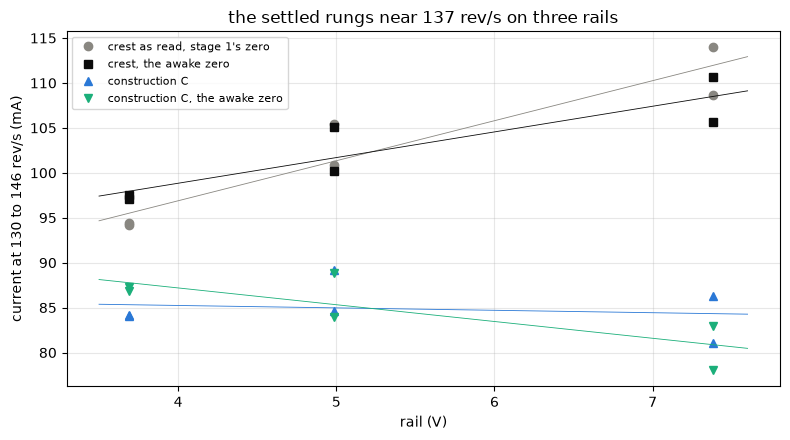

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for col, mk, color, lab in (
        ("i_crest_ma", "o", MUTED, "crest as read, stage 1's zero"),
        ("i_awake_ma", "s", INK, "crest, the awake zero"),
        ("i_c_ma", "^", BLUE, "construction C"),
        ("i_c_awake_ma", "v", GREEN, "construction C, the awake zero")):
    ax.plot(AT["rail_v"], AT[col], mk, color=color, label=lab)
    f = RAIL_SLOPES[col]
    xx = np.array([3.5, 7.6])
    ax.plot(xx, f["intercept"] + f["slope"] * xx, color=color, lw=0.6)
figures.label(ax, x="rail (V)", y="current at 130 to 146 rev/s (mA)",
              title="the settled rungs near 137 rev/s on three rails")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The current of the six rungs at 130 to 146 rev/s against the rail, as read and under construction C, each with stage 1's zero and with the awake zero, and a line through each.

As read, the crest current climbs +4.45 +/- 0.79 mA per volt of rail, 5.7 sigma, the ladder's number. Under construction C the six read 84.1, 84.0, 84.6, 89.2, 81.0 and 86.3 mA and slope -0.27 +/- 0.80 mA per volt, -0.3 sigma. With the crest term out, the drag is a function of speed and not of the rail, high confidence. Left free in a fit over every steady rung, the crest term comes out at 4.64 +/- 0.75 mS against the meter's 4.75, so the friction read confirms the resistance notebook's crest term from a third dataset, likely. The awake zero in place of stage 1's offset leaves a rail trend of -2.7 sigma under C, so stage 1's zero with g is the reading that closes.

## 4. Route 1, the drag against speed

Kt times the settled-equivalent current under construction C, against the tach's speed, per direction. The line T = Tc + b w is fitted per direction over tiers 1 and 2. Beside it run the same line on tier 1 alone, on every rung, with the awake zero and with no crest term, and a square term and the type's square-root form as other shapes.

In [22]:
def fit_poly_terms(w, y, order=1, sigma=None):
    """y = c0 + c1 w (+ c2 w^2) by least squares: coefficients, standard
    errors (scaled by the residual chi2 when sigma is given), residuals,
    rms and count."""
    w, y = np.asarray(w, float), np.asarray(y, float)
    ok = np.isfinite(w) & np.isfinite(y)
    w, y = w[ok], y[ok]
    X = np.vander(w, order + 1, increasing=True)
    s = None if sigma is None else np.asarray(sigma, float)[ok]
    Xw, yw = (X, y) if s is None else (X / s[:, None], y / s)
    coef, *_ = np.linalg.lstsq(Xw, yw, rcond=None)
    resid = y - X @ coef
    dof = max(len(y) - (order + 1), 1)
    if s is not None:
        chi2 = float(((resid / s) ** 2).sum())
        cov = np.linalg.inv(Xw.T @ Xw) * max(chi2 / dof, 1.0)
    else:
        cov = np.linalg.inv(X.T @ X) * (resid ** 2).sum() / dof
    return {"coef": coef, "se": np.sqrt(np.diag(cov)), "resid": resid,
            "rms": float(np.sqrt((resid ** 2).mean())), "n": int(len(y)),
            "cov": cov}


def trend_sigma(x, resid):
    """The residuals' slope on x over its standard error."""
    f = results.fit_line(x, resid)
    return f["slope"] / f["slope_se"] if f["slope_se"] > 0 else np.nan

In [23]:
def flat_band(w, resid, edges):
    """(bins, (lo, hi)): per speed bin the residuals' mean, se and count;
    a bin is flat when its mean sits within 2 se or half the rms of
    zero, and the band is the widest run of flat bins."""
    w, r = np.asarray(w, float), np.asarray(resid, float)
    rms = np.sqrt(np.nanmean(r ** 2))
    rows = []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (w >= a) & (w < b) & np.isfinite(r)
        if m.sum() == 0:
            continue
        mean = r[m].mean()
        se = r[m].std(ddof=1) / np.sqrt(m.sum()) if m.sum() > 1 else rms
        rows.append({"lo": a, "hi": b, "n": int(m.sum()), "mean": mean,
                     "se": se, "flat": abs(mean) <= max(2 * se, 0.5 * rms)})
    tab = pd.DataFrame(rows)
    best, run = (None, None), []
    for _, row in tab.iterrows():
        run = run + [row] if row["flat"] else []
        if run and (best[0] is None
                    or run[-1]["hi"] - run[0]["lo"] > best[1] - best[0]):
            best = (run[0]["lo"], run[-1]["hi"])
    return tab, best

In [24]:
EDGES_R1 = np.array([0, 75, 150, 225, 300, 375, 500])   # rev/s bins
W300 = (300 * RPS) ** 2                 # the square term read at 300 rev/s


def fit_route1(g, col):
    """(row, line fit, bins) of T = Tc + b w on rungs g, with the square
    term and the square-root form beside it on five rungs or more."""
    f1 = fit_poly_terms(g["w_rad_s"], g[col], 1)
    out = {"n": f1["n"], "Tc_uNm": f1["coef"][0], "Tc_se": f1["se"][0],
           "b": f1["coef"][1], "b_se": f1["se"][1], "rms": f1["rms"],
           "rail_trend_sigma": trend_sigma(g["rail_v"], f1["resid"]),
           "w_min": g["rev_s"].min(), "w_max": g["rev_s"].max()}
    if len(g) >= 5:
        f2 = fit_poly_terms(g["w_rad_s"], g[col], 2)
        fs = fit_poly_terms(np.sqrt(g["w_rad_s"]), g[col], 1)
        out.update(c2_at_300=f2["coef"][2] * W300,
                   c2_se=f2["se"][2] * W300,
                   c2_sigma=f2["coef"][2] / f2["se"][2], rms_quad=f2["rms"],
                   rms_sqrt=fs["rms"])
    tab, band = flat_band(g["rev_s"], f1["resid"], EDGES_R1)
    out.update(flat_lo=band[0], flat_hi=band[1])
    return out, f1, tab

In [25]:
VARIANTS = (
    ("tier 1", R["tier"] == 1, "T_uNm"),
    ("tiers 1+2", R["tier"] <= 2, "T_uNm"),
    ("all, settled-equiv.", R["tier"] <= 3, "T_uNm"),
    ("tiers 1+2, awake zero", R["tier"] <= 2, "T_uNm_awake"),
    ("tiers 1+2, no crest term", R["tier"] <= 2, "T_uNm_A"))
FITS, fit_rows = {}, []
for label, sel, col in VARIANTS:
    for d in (1, -1):
        g = R[sel & (R["dir"] == d)]
        if len(g) < 3:
            continue
        out, f1, tab = fit_route1(g, col)
        fit_rows.append({"fit": label, "dir": d, **out})
        FITS[(label, d)] = (f1, g, tab)
FIT_TABLE = pd.DataFrame(fit_rows)
for _, r in FIT_TABLE.iterrows():
    extra = (f"; square term {r['c2_at_300']:+.0f} +/- {r['c2_se']:.0f} "
             f"uN m at 300 rev/s ({r['c2_sigma']:+.1f} sigma), square root "
             f"rms {r['rms_sqrt']:.1f}" if np.isfinite(r["c2_sigma"])
             else "")
    print(f"{r['fit']}, {r['dir']:+d}: n {r['n']}, Tc {r['Tc_uNm']:.1f} "
          f"+/- {r['Tc_se']:.1f} uN m, b {r['b']:.4f} +/- {r['b_se']:.4f}, "
          f"rms {r['rms']:.1f}, rail trend {r['rail_trend_sigma']:+.1f} "
          f"sigma, {r['w_min']:.0f} to {r['w_max']:.0f} rev/s, flat "
          f"{r['flat_lo']:.0f} to {r['flat_hi']:.0f}" + extra)

tier 1, +1: n 4, Tc 41.5 +/- 12.7 uN m, b 0.0696 +/- 0.0159, rms 2.6, rail trend +0.7 sigma, 94 to 138 rev/s, flat 75 to 150
tier 1, -1: n 8, Tc 52.6 +/- 4.0 uN m, b 0.0480 +/- 0.0051, rms 3.2, rail trend -0.8 sigma, 57 to 198 rev/s, flat 0 to 225; square term -22 +/- 66 uN m at 300 rev/s (-0.3 sigma), square root rms 3.2
tiers 1+2, +1: n 11, Tc 54.3 +/- 4.8 uN m, b 0.0514 +/- 0.0054, rms 5.7, rail trend +0.1 sigma, 57 to 217 rev/s, flat 75 to 225; square term -126 +/- 54 uN m at 300 rev/s (-2.3 sigma), square root rms 4.7
tiers 1+2, -1: n 10, Tc 55.0 +/- 3.0 uN m, b 0.0443 +/- 0.0032, rms 3.2, rail trend -0.4 sigma, 57 to 223 rev/s, flat 0 to 225; square term -39 +/- 39 uN m at 300 rev/s (-1.0 sigma), square root rms 3.0
all, settled-equiv., +1: n 18, Tc 71.3 +/- 4.8 uN m, b 0.0286 +/- 0.0033, rms 10.3, rail trend -0.3 sigma, 32 to 439 rev/s, flat 75 to 150; square term -60 +/- 7 uN m at 300 rev/s (-8.0 sigma), square root rms 7.6
all, settled-equiv., -1: n 18, Tc 68.7 +/- 3.9 uN m, b

The carried fit, tiers 1 and 2, reads Tc 54.3 +/- 4.8 uN m and b 0.0514 +/- 0.0054 uN m s/rad on +1, rms 5.7 uN m over 11 rungs from 57 to 217 rev/s, and Tc 55.0 +/- 3.0 and b 0.0443 +/- 0.0032 on -1, rms 3.2 over 10 rungs from 57 to 223. Neither leaves a trend on the rail, +0.1 and -0.4 sigma. A square term reads -126 +/- 54 and -39 +/- 39 uN m at 300 rev/s, -2.3 and -1.0 sigma, and the square-root form fits to rms 4.7 and 3.0, so over this range the data do not choose a shape beyond the line.

The variants. Tier 1 alone has 4 rungs on +1, too few for a line, Tc 41.5 +/- 12.7. With the awake zero the pair barely moves, Tc 55.4 and 55.1 uN m, but the -1 residuals trend on the rail at -3.0 sigma. With no crest term the Coulomb term reads 78.6 and 81.4 uN m with rail trends of +3.7 and +6.4 sigma, so that reading does not hold. On every rung with the settled-equivalent the line bends, b falls to 0.0286 and 0.0256 and the square term reads -8.0 sigma on +1. That bend comes from the correction on the run-up rungs (section 6 shows them under both routes).

In [26]:
for d in (1, -1):
    f1, g, tab = FITS[("tiers 1+2", d)]
    g = g.assign(resid_uNm=f1["resid"],
                 resid_ma=ma_at_kt(f1["resid"] * 1e-6))
    print(f"direction {d:+d}:")
    print(g[["volts_set", "duty_set", "rev_s", "T_uNm", "resid_uNm",
             "resid_ma", "tier"]].round(2).to_string(index=False))
    print("  bins: " + "; ".join(
        f"{int(b.lo)}-{int(b.hi)} rev/s n {b.n} {b['mean']:+.1f} +/- "
        f"{b.se:.1f}" + ("" if b.flat else " not flat")
        for _, b in tab.iterrows()))
for v, du, d in ((3.7, 30, 1), (3.7, 20, 1)):
    r = R[(R.volts_set == v) & (R.duty_set == du) & (R.dir == d)].iloc[0]
    lift = (r["i_settled_ma"] / r["i_c_ma"] - 1) * 100
    print(f"{v} V {du} % {d:+d}: settle {r['settle_pct']:+.1f} %, the "
          f"settled-equivalent {lift:+.1f} % over the window's current")

direction +1:
 volts_set  duty_set  rev_s  T_uNm  resid_uNm  resid_ma  tier
       3.7        20  58.34  64.33      -8.77     -7.57     2
       3.7        30  93.76  97.98      13.44     11.59     2
       3.7        40 137.51  97.65      -1.01     -0.87     1
       3.7        60 217.41 119.26      -5.19     -4.48     2
       5.0        15  56.73  68.67      -3.91     -3.38     2
       5.0        20  81.45  79.89      -0.67     -0.58     2
       5.0        30 136.36 104.21       5.93      5.11     1
       5.0        40 192.66 116.18      -0.27     -0.24     2
       7.4        15  93.96  82.49      -2.11     -1.82     1
       7.4        20 134.88 101.73       3.92      3.38     1
       7.4        30 216.40 122.78      -1.34     -1.15     2
  bins: 0-75 rev/s n 2 -6.3 +/- 2.4 not flat; 75-150 rev/s n 6 +3.2 +/- 2.4; 150-225 rev/s n 3 -2.3 +/- 1.5
direction -1:
 volts_set  duty_set  rev_s  T_uNm  resid_uNm  resid_ma  tier
       3.7        30  95.61  86.28       4.65      4.01   

Per rung the residuals sit within 6 uN m, 5.1 mA, but two. The 3.7 V 30 % +1 rung reads +13.44 uN m. Its -4.2 % settle makes the settled-equivalent read +10.0 % over the window's current on a rung that is steady. The 3.7 V 20 % +1 rung reads -8.77. Binned by 75 rev/s the residuals are flat from 75 to 225 rev/s on +1, where the 0 to 75 bin's two rungs read -6.3 +/- 2.4, and from 0 to 225 on -1.

In [27]:
POOLED = fit_poly_terms(g12["w_rad_s"], g12["T_uNm"], 1)
CARRIED = {d: FITS[("tiers 1+2", d)][0] for d in (1, -1)}
SPLIT = {}
for i, name in ((0, "Tc"), (1, "b")):
    diff = CARRIED[1]["coef"][i] - CARRIED[-1]["coef"][i]
    err = np.hypot(CARRIED[1]["se"][i], CARRIED[-1]["se"][i])
    SPLIT[name] = (diff, err, diff / err)
pc, ps = POOLED["coef"], POOLED["se"]
print(f"pooled, tiers 1+2: Tc {pc[0]:.1f} +/- {ps[0]:.1f} uN m "
      f"({ma_at_kt(pc[0] * 1e-6):.1f} mA), b {pc[1]:.4f} +/- {ps[1]:.4f} "
      f"uN m s/rad ({ma_at_kt(pc[1] * 1e-6) * RPS:.3f} mA per rev/s), rms "
      f"{POOLED['rms']:.1f} uN m ({ma_at_kt(POOLED['rms'] * 1e-6):.1f} "
      f"mA), n {POOLED['n']}")
for name, (diff, err, sig) in SPLIT.items():
    print(f"{name}(+1) - {name}(-1) = {diff:+.4g} +/- {err:.2g} "
          f"({sig:+.1f} sigma)")


def drag_route1(w_rev_s, d=None):
    """Route 1's drag at the motor, N m: one direction's pair, or the
    pooled pair when d is None."""
    c = POOLED["coef"] if d is None else CARRIED[d]["coef"]
    return (c[0] + c[1] * np.asarray(w_rev_s, float) * RPS) * 1e-6

pooled, tiers 1+2: Tc 55.1 +/- 3.3 uN m (47.5 mA), b 0.0474 +/- 0.0036 uN m s/rad (0.257 mA per rev/s), rms 5.5 uN m (4.7 mA), n 21
Tc(+1) - Tc(-1) = -0.7296 +/- 5.7 (-0.1 sigma)
b(+1) - b(-1) = +0.007054 +/- 0.0063 (+1.1 sigma)


The directions do not separate. Tc(+1) less Tc(-1) is -0.73 +/- 5.7 uN m, -0.1 sigma, and b(+1) less b(-1) is +0.0071 +/- 0.0063, +1.1 sigma. Pooled, the pair is Tc 55.1 +/- 3.3 uN m, 47.5 mA at Ke, and b 0.0474 +/- 0.0036 uN m s/rad, 0.257 mA per rev/s, rms 5.5 uN m (4.7 mA) over 21 rungs. Confidence moderate, from 21 rungs of one sitting.

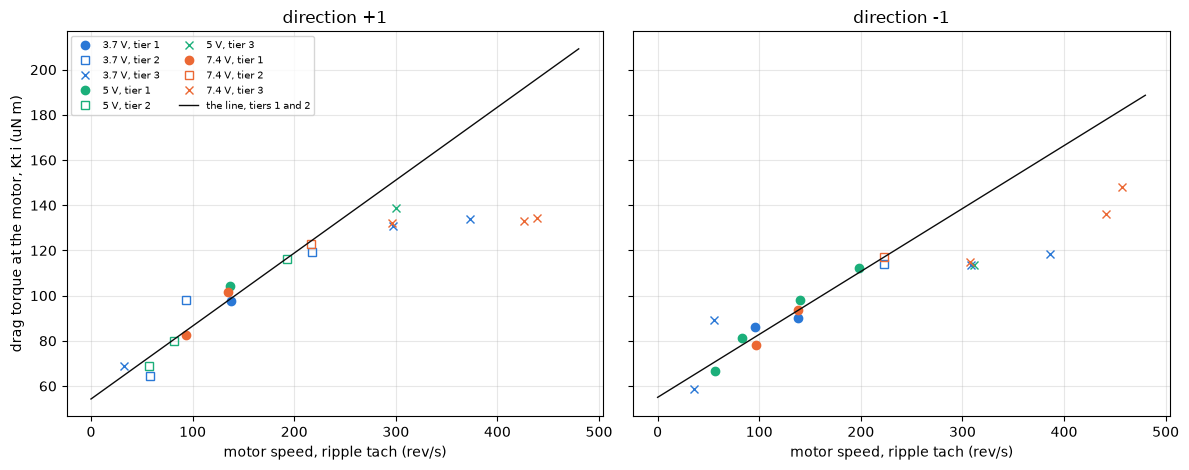

In [28]:
RAIL_COLOR = {3.7: BLUE, 5.0: GREEN, 7.4: ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
ww = np.linspace(0, 480, 50)
for ax, d in zip(axes, (1, -1)):
    for v, g in R[R["dir"] == d].groupby("volts_set"):
        c = RAIL_COLOR[v]
        for tier, mk in ((1, "o"), (2, "s"), (3, "x")):
            gg = g[g["tier"] == tier]
            ax.plot(gg["rev_s"], gg["T_uNm"], mk, color=c, ms=6,
                    mfc=c if tier == 1 else "none",
                    label=f"{v:g} V, tier {tier}")
    ax.plot(ww, u_nm(drag_route1(ww, d)), color=INK, lw=1,
            label="the line, tiers 1 and 2")
    figures.label(ax, x="motor speed, ripple tach (rev/s)",
                  title=f"direction {d:+d}")
axes[0].set_ylabel("drag torque at the motor, Kt i (uN m)")
axes[0].legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. Route 1's drag torque against speed per direction, one color per rail, filled circles tier 1, open squares tier 2 and crosses the run-up rungs of tier 3, with the line through tiers 1 and 2. The three rails fall on one curve. The run-up rungs sit under the line's extension, the settled-equivalent's bias on a spin still accelerating.

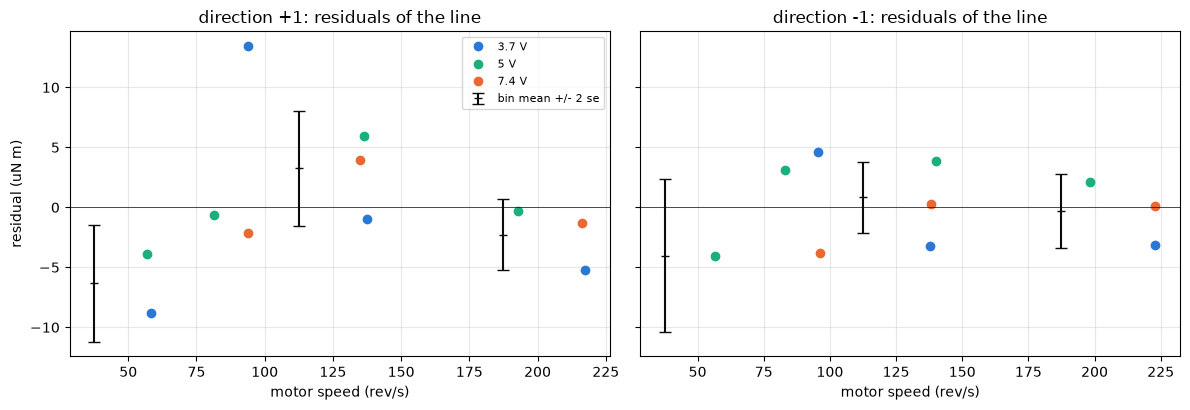

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, d in zip(axes, (1, -1)):
    f1, g, tab = FITS[("tiers 1+2", d)]
    for v, gg in g.assign(resid=f1["resid"]).groupby("volts_set"):
        ax.plot(gg["rev_s"], gg["resid"], "o", color=RAIL_COLOR[v],
                label=f"{v:g} V")
    mid = (tab["lo"] + tab["hi"]) / 2
    ax.errorbar(mid, tab["mean"], yerr=2 * tab["se"], fmt="_", color=INK,
                capsize=4, label="bin mean +/- 2 se")
    ax.axhline(0, color=INK, lw=0.5)
    figures.label(ax, x="motor speed (rev/s)",
                  title=f"direction {d:+d}: residuals of the line")
axes[0].set_ylabel("residual (uN m)")
axes[0].legend(fontsize=8)
figures.finish(fig)

What you are looking at. The carried line's residual per rung, one color per rail, and each 75 rev/s bin's mean with 2 se. Nothing in them orders by rail.

## 5. Route 2, the coasts

The free coast reads the drag with nothing electrical in it. With the bridge open the winding carries no current, so J times the deceleration is the drag torque. Each coast's EMF from the cut over the sweep's rest tap zero, with open rows bridged, gets a quadratic every 0.5 ms over +/- 5 ms down to the stop, its level over Ke the speed and its slope over Ke the deceleration. The run-up coasts and the ladder's own coasts are binned by 25 rev/s per direction, the median per bin with its sd over the fits.

In [30]:
RUNUP_SETS = sorted(p.name for p in (PAIR_DIR / "run-up").iterdir()
                    if p.is_dir())
coast_tabs = []
for s in RUNUP_SETS:
    cy = cycles.load(PAIR_DIR / "run-up" / s)
    for _, r in cy.iterrows():
        df, zero_i, zero_e = load_sweep(cy.folder(r["k"]))
        for d, spin, cst in coast.pairs(df):
            tab, _, _, _, _ = coast_at_cut(cst, d, zero_e)
            coast_tabs.append(tab.assign(set=s, k=int(r["k"]), dir=d,
                                         sitting=int(s.split("-")[-1])))
RC = pd.concat(coast_tabs, ignore_index=True)
RC["rev_s"] = RC["w"] / RPS
RC["decel"] = -RC["alpha"]              # rad/s2, positive = slowing
per_coast = RC.groupby(["set", "k", "dir"])["t_coast"].max() * 1e3
print(f"{len(RUNUP_SETS)} sets {RUNUP_SETS}")
print(f"{per_coast.size} coasts, {len(RC)} fits, each coast's last fit "
      f"{per_coast.min():.0f} to {per_coast.max():.0f} ms after the cut")
LC = LADDER_DECEL.copy()                # the ladder's own coasts
LC["rev_s"] = LC["w"] / RPS
LC["decel"] = -LC["alpha"]
LC = LC[LC["rev_s"] > 5]
print(f"ladder coasts: {LC.groupby(['set', 'k', 'dir']).ngroups} coasts, "
      f"{len(LC)} fits over 5 rev/s")

6 sets ['runup-close-1', 'runup-close-6', 'runup-close-7', 'runup-open-1', 'runup-open-6', 'runup-open-7']
36 coasts, 12558 fits, each coast's last fit 164 to 198 ms after the cut
ladder coasts: 108 coasts, 17455 fits over 5 rev/s


In [31]:
BIN = 25.0                              # rev/s, the speed bin
EDGES = np.arange(0, 525, BIN)
MIN_FITS = 5                            # fits a bin needs


def bins(tab, by=("dir",)):
    """Median deceleration per speed bin with its sd and se over the
    fits, and the torque J times it with J's bracket."""
    tab = tab.assign(bin=np.digitize(tab["rev_s"], EDGES) - 1)
    g = tab.groupby(list(by) + ["bin"]).agg(
        rev_s=("rev_s", "mean"), decel=("decel", "median"),
        sd=("decel", "std"), n=("decel", "size")).reset_index()
    g["se"] = g["sd"] / np.sqrt(g["n"].clip(lower=1))
    g["T_uNm"] = u_nm(J * g["decel"])
    g["T_lo_uNm"] = u_nm(J_LO * g["decel"])
    g["T_hi_uNm"] = u_nm(J_HI * g["decel"])
    return g[g["n"] >= MIN_FITS]


RB = bins(RC)                           # the run-up coasts
LB = bins(LC)                           # the ladder coasts
LB_RAIL = bins(LC, by=("dir", "volts_set"))
RB_SITTING = bins(RC, by=("dir", "sitting"))
show(RB[["dir", "rev_s", "decel", "sd", "n", "T_uNm", "T_lo_uNm",
         "T_hi_uNm"]], n=None)

,dir,rev_s,decel,sd,n,T_uNm,T_lo_uNm,T_hi_uNm
0,-1,17.745,7530.258,2683.170,382,48.443,44.128,53.274
1,-1,37.001,9077.827,2183.757,628,58.399,53.197,64.222
2,-1,62.230,10873.999,2063.711,508,69.954,63.723,76.929
3,-1,87.168,11724.423,2061.988,481,75.425,68.707,82.946
4,-1,112.159,12915.745,1863.445,439,83.089,75.688,91.374
5,-1,137.081,14859.036,2088.021,380,95.590,87.076,105.122
6,-1,162.390,15523.071,2086.365,362,99.862,90.967,109.820
7,-1,187.416,16202.558,1977.356,347,104.233,94.949,114.627
8,-1,212.391,17280.333,1799.392,327,111.166,101.265,122.252
9,-1,237.474,18340.707,1953.455,306,117.988,107.479,129.753


In [32]:
def route2_at(d, rev_s, table=None):
    """Route 2's drag in uN m at `rev_s`, interpolated in a bin table."""
    b = RB if table is None else table
    g = b[b["dir"] == d].sort_values("rev_s")
    return np.interp(rev_s, g["rev_s"], g["T_uNm"])


check = []
for d in (1, -1):
    for key, ent in RUNUP["coast_decel_by_speed_rad_s2"][f"{d:+d}"].items():
        here = RB[(RB["dir"] == d)
                  & (np.abs(RB["rev_s"] - float(key.split()[0])) < 13)]
        if len(here):
            check.append(here["decel"].iloc[0] / -ent["value"])
check = pd.Series(check)
print(f"against the run-up result's bins: {check.mean():.3f} sd "
      f"{check.std():.3f} over {len(check)} bins (the result pooled "
      f"{len(RUNUP['capture'].split(','))} sets, this reads "
      f"{len(RUNUP_SETS)})")
for at in (18, 137, 300, 460):
    T = [route2_at(d, at) for d in (1, -1)]   # interpolated in the bins
    print(f"at {at} rev/s: {T[0]:.1f} (+1) and {T[1]:.1f} (-1) uN m = "
          f"{ma_at_kt(T[0] * 1e-6):.1f} and {ma_at_kt(T[1] * 1e-6):.1f} mA")
both = RB.pivot_table(index="bin", columns="dir", values="decel")
mid = both[(both.index * BIN >= 50) & (both.index * BIN < 400)]
gap = (mid[1] / mid[-1] - 1) * 100
print(f"+1 over -1 from 50 to 400 rev/s: {gap.min():+.1f} to "
      f"{gap.max():+.1f} %")

against the run-up result's bins: 0.991 sd 0.011 over 39 bins (the result pooled 4 sets, this reads 6)
at 18 rev/s: 51.1 (+1) and 48.6 (-1) uN m = 44.1 and 41.9 mA
at 137 rev/s: 93.1 (+1) and 95.5 (-1) uN m = 80.4 and 82.4 mA
at 300 rev/s: 138.5 (+1) and 135.8 (-1) uN m = 119.5 and 117.1 mA
at 460 rev/s: 183.8 (+1) and 173.5 (-1) uN m = 158.6 and 149.7 mA
+1 over -1 from 50 to 400 rev/s: -3.9 to +3.9 %


The six run-up sets hold 36 coasts and 12558 fits, each coast read until 164 to 198 ms after the cut. The ladder's 108 coasts add 17455 fits above 5 rev/s. The run-up bins read 0.991 sd 0.011 of the run-up result's, which pooled 4 sets where this reads 6, sitting 7's two among them.

Through J of 6.43e-9 kg m2 the run-up coasts give 51.1 (+1) and 48.6 (-1) uN m at 18 rev/s, 93.1 and 95.5 at 137, 138.5 and 135.8 at 300, and 183.8 and 173.5 at 460. The two directions' decelerations agree within -3.9 to +3.9 % from 50 to 400 rev/s.

In [33]:
piv = LB_RAIL.pivot_table(index=["dir", "bin"], columns="volts_set",
                          values="decel")
RAIL_RATIO = piv.div(piv[5.0], axis=0)   # each rail block over 5 V's
for v in (3.7, 7.4):
    x = RAIL_RATIO[v].dropna()
    print(f"ladder coasts {v} V / 5 V: {x.mean():.3f} sd {x.std():.3f} se "
          f"{x.std() / np.sqrt(len(x)):.3f} (n {len(x)} bins)")
order = SPINS.groupby("volts_set")["t_start"].min().sort_values()
print("the ladder's rail blocks in the order they ran: "
      + ", ".join(f"{v:g} V" for v in order.index))
LAD_RUN = RB.merge(LB, on=["dir", "bin"], suffixes=("_run", "_lad"))
LAD_RUN["ratio"] = LAD_RUN["decel_lad"] / LAD_RUN["decel_run"]
print(f"ladder coasts over run-up coasts: {LAD_RUN['ratio'].mean():.3f} sd"
      f" {LAD_RUN['ratio'].std():.3f} (n {len(LAD_RUN)} bins)")
x = LAD_RUN[(LAD_RUN["dir"] == 1) & (LAD_RUN["rev_s_run"] < 150)]
print(f"  +1 under 150 rev/s: {x['ratio'].min():.3f} to "
      f"{x['ratio'].max():.3f}")
by_sit = RB_SITTING.pivot_table(index=["dir", "bin"], columns="sitting",
                                values="decel")
SITTING_RATIO = {}
for sit in (6, 7):
    x = (by_sit[sit] / by_sit[1]).dropna()
    SITTING_RATIO[sit] = x
    print(f"run-up coasts, sitting {sit} / 1: {x.mean():.3f} sd "
          f"{x.std():.3f} (n {len(x)} bins)")

ladder coasts 3.7 V / 5 V: 0.984 sd 0.039 se 0.008 (n 24 bins)
ladder coasts 7.4 V / 5 V: 0.962 sd 0.037 se 0.008 (n 24 bins)
the ladder's rail blocks in the order they ran: 3.7 V, 5 V, 7.4 V
ladder coasts over run-up coasts: 1.026 sd 0.037 (n 38 bins)
  +1 under 150 rev/s: 1.056 to 1.118
run-up coasts, sitting 6 / 1: 0.989 sd 0.030 (n 39 bins)
run-up coasts, sitting 7 / 1: 0.968 sd 0.033 (n 39 bins)


In [34]:
TIME_BINS = [5, 15, 30, 60, 120, 400]   # ms after the cut
med = RB[["dir", "bin", "decel"]].rename(columns={"decel": "decel_bin"})
RC2 = RC.assign(bin=np.digitize(RC["rev_s"], EDGES) - 1).merge(
    med, on=["dir", "bin"], how="inner")
RC2["excess"] = RC2["decel"] / RC2["decel_bin"] - 1
EXCESS = RC2.groupby(pd.cut(RC2["t_coast"] * 1e3, TIME_BINS),
                     observed=True)["excess"].median() * 100
print("deceleration over its bin's median by time after the cut, %:")
print(EXCESS.round(1).to_string())
for m in TYPE_NL:
    e = TYPE_NL[m]["coast_relax_early_pct"]
    print(f"{m}, stage 2: {e['value']:.1f} % ({e['lo']:.1f} to "
          f"{e['hi']:.1f}) over its late curve in the first 8 ms")

deceleration over its bin's median by time after the cut, %:
t_coast
(5, 15]       0.1
(15, 30]      0.2
(30, 60]      0.2
(60, 120]     0.0
(120, 400]   -0.3
mg90-b, stage 2: 9.2 % (7.3 to 9.2) over its late curve in the first 8 ms
mg90-c, stage 2: 4.4 % (3.6 to 4.4) over its late curve in the first 8 ms


The coasts also read the servo's state.

- Run-in. The run-up coasts of sitting 6 read 0.989 sd 0.030 and those of sitting 7 0.968 sd 0.033 of sitting 1's at matched bins. The ladder, in sitting 1, reads 1.026 sd 0.037 of the pooled run-up coasts, and its +1 coasts under 150 rev/s 1.056 to 1.118. The drag falls from sitting to sitting, likely the train running in.
- The rail blocks. The ladder's 7.4 V coasts decelerate at 0.962 sd 0.037 of the 5 V block's over 24 bins, se 0.008, and the 3.7 V block's at 0.984. A coast carries no rail, so this is a state of the grease or the brushes. The blocks ran 3.7 V, 5 V, 7.4 V in that order, so time and the heat of the 7.4 V spins are confounded with the rail (discrepancy 2).
- No early excess. The deceleration 5 to 15 ms after the cut reads +0.1 % over its bin's median, and later 0.2, 0.2, 0.0 and -0.3 %. The type's bare motors read 9.2 % (mg90-b) and 4.4 % (mg90-c) over their late curve in the first 8 ms. Here the drag the drive held and the drag early in the coast are the same, which the settled-equivalent and the comparison with route 1 both rely on.

In [35]:
EDGES_R2 = np.array([0, 75, 150, 225, 300, 375, 450, 525])
FITS2, rows = {}, []
for d in (1, -1):
    g = RB[(RB["dir"] == d) & (RB["rev_s"] < 480)]
    w, T = g["rev_s"].to_numpy() * RPS, g["T_uNm"].to_numpy()
    sig = u_nm(J * g["se"]).to_numpy()      # weights from the bin se
    f1 = fit_poly_terms(w, T, 1, sigma=sig)
    f2 = fit_poly_terms(w, T, 2, sigma=sig)
    fsq = fit_poly_terms(np.sqrt(w), T, 1, sigma=sig)
    tab, band = flat_band(g["rev_s"], f1["resid"], EDGES_R2)
    _, band2 = flat_band(g["rev_s"], f2["resid"], EDGES_R2)
    rows.append({"dir": d, "n_bins": f1["n"], "Tc_uNm": f1["coef"][0],
                 "Tc_se": f1["se"][0], "b": f1["coef"][1],
                 "b_se": f1["se"][1], "rms_line": f1["rms"],
                 "flat_line": band, "c2_at_300": f2["coef"][2] * W300,
                 "c2_sigma": f2["coef"][2] / f2["se"][2],
                 "rms_quad": f2["rms"], "flat_quad": band2,
                 "rms_sqrt": fsq["rms"]})
    FITS2[d] = {"line": f1, "quad": f2, "g": g, "tab": tab}
FIT2_TABLE = pd.DataFrame(rows)
for _, r in FIT2_TABLE.iterrows():
    print(f"{r['dir']:+d}: line Tc {r['Tc_uNm']:.1f} +/- {r['Tc_se']:.1f} "
          f"uN m, b {r['b']:.4f} +/- {r['b_se']:.4f}, rms "
          f"{r['rms_line']:.1f}, flat {r['flat_line']}; square term "
          f"{r['c2_at_300']:+.1f} uN m at 300 rev/s ({r['c2_sigma']:+.1f} "
          f"sigma), rms {r['rms_quad']:.1f}, flat {r['flat_quad']}; "
          f"square root rms {r['rms_sqrt']:.1f}; {r['n_bins']} bins")

+1: line Tc 47.6 +/- 1.0 uN m, b 0.0485 +/- 0.0008, rms 2.5, flat (150, 525); square term -1.5 uN m at 300 rev/s (-0.4 sigma), rms 2.5, flat (150, 525); square root rms 8.6; 19 bins
-1: line Tc 51.6 +/- 1.3 uN m, b 0.0442 +/- 0.0009, rms 3.8, flat (0, 450); square term -13.4 uN m at 300 rev/s (-4.7 sigma), rms 2.0, flat (0, 225); square root rms 4.5; 20 bins


In [36]:
for d in (1, -1):
    g, f1, f2 = FITS2[d]["g"], FITS2[d]["line"], FITS2[d]["quad"]
    print(f"direction {d:+d}, the line's residuals (rev/s: uN m):")
    print("  " + ", ".join(f"{w:.0f}: {e:+.1f}"
                           for w, e in zip(g["rev_s"], f1["resid"])))
    print("  bins: " + "; ".join(
        f"{int(b.lo)}-{int(b.hi)} {b['mean']:+.1f} +/- {b.se:.1f}"
        + ("" if b.flat else " not flat")
        for _, b in FITS2[d]["tab"].iterrows()))
    top = g["rev_s"] > 400
    print(f"  the quadratic's residuals over 400 rev/s: "
          + ", ".join(f"{e:+.1f}" for e in f2["resid"][top.to_numpy()]))
LOW2 = {}
for d in (1, -1):
    g = RB[(RB["dir"] == d) & (RB["rev_s"] < 230)]
    LOW2[d] = fit_poly_terms(g["rev_s"] * RPS, g["T_uNm"], 1,
                             sigma=u_nm(J * g["se"]))
    c, s = LOW2[d]["coef"], LOW2[d]["se"]
    print(f"under 230 rev/s, {d:+d}: Tc {c[0]:.1f} +/- {s[0]:.1f} uN m, b "
          f"{c[1]:.4f} +/- {s[1]:.4f}, rms {LOW2[d]['rms']:.1f}, n "
          f"{LOW2[d]['n']}")

direction +1, the line's residuals (rev/s: uN m):
  19: -2.3, 37: -2.3, 62: +0.6, 87: +1.1, 112: +1.9, 137: +3.8, 162: +2.0, 187: -0.3, 212: -1.5, 237: -3.7, 262: -1.6, 287: +1.3, 312: -2.4, 338: +1.5, 362: -0.2, 387: +0.6, 412: +6.9, 437: -2.7, 453: -2.0
  bins: 0-75 -1.3 +/- 1.0; 75-150 +2.2 +/- 0.8 not flat; 150-225 +0.1 +/- 1.0; 225-300 -1.3 +/- 1.4; 300-375 -0.4 +/- 1.1; 375-450 +1.6 +/- 2.8; 450-525 -2.0 +/- 2.5
  the quadratic's residuals over 400 rev/s: +7.5, -2.0, -1.1
direction -1, the line's residuals (rev/s: uN m):
  18: -8.1, 37: -3.5, 62: +1.1, 87: -0.4, 112: +0.3, 137: +5.9, 162: +3.2, 187: +0.6, 212: +0.6, 237: +0.4, 262: +0.5, 287: +1.1, 312: +0.6, 338: +2.1, 362: +2.5, 387: +1.0, 412: -3.9, 438: -6.0, 462: -5.8, 479: -8.6
  bins: 0-75 -3.5 +/- 2.6; 75-150 +1.9 +/- 2.0; 150-225 +1.4 +/- 0.9; 225-300 +0.7 +/- 0.2; 300-375 +1.7 +/- 0.6; 375-450 -3.0 +/- 2.1; 450-525 -7.2 +/- 1.4 not flat
  the quadratic's residuals over 400 rev/s: -1.1, -1.8, +0.1, -1.5
under 230 rev/s, 

The line through the run-up bins, weighted by each bin's se, reads Tc 47.6 +/- 1.0 uN m and b 0.0485 +/- 0.0008 uN m s/rad on +1, rms 2.5, and Tc 51.6 +/- 1.3 and b 0.0442 +/- 0.0009 on -1, rms 3.8. The +1 residuals stay within 4 uN m from 150 to 400 rev/s and read +6.9 at 412, and the 75 to 150 bin sits +2.2 +/- 0.8 off the line. The -1 drag follows its line to 400 rev/s and then falls 3.9 to 8.6 uN m under it. A square term on -1 reads -13.4 uN m at 300 rev/s, -4.7 sigma, and takes the rms from 3.8 to 2.0, where on +1 it reads -1.5, -0.4 sigma. The -1 drag at the top is concave and the +1 drag is not, high confidence statistically, cause open (discrepancy 5). The run-up notebook found a -1 split at its top speeds, and it shows here in the coast, which has no tach in it.

Under 230 rev/s, route 1's range, the lines read Tc 47.0 +/- 1.4 and 48.2 +/- 2.0 uN m and b 0.0500 +/- 0.0018 and 0.0492 +/- 0.0025.

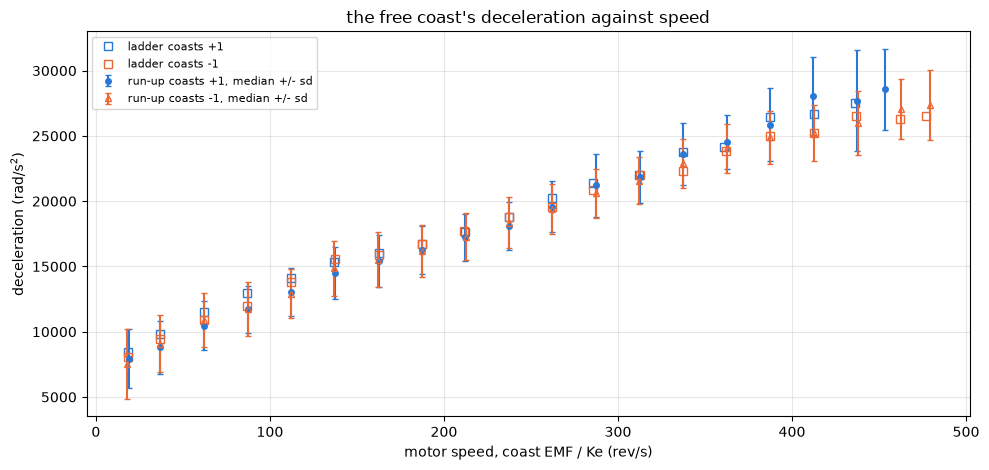

In [37]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for d, c in ((1, BLUE), (-1, ORANGE)):
    g = RB[RB["dir"] == d]
    ax.errorbar(g["rev_s"], g["decel"], yerr=g["sd"], ms=4, capsize=2,
                **figures.direction_style(d, c),
                label=f"run-up coasts {d:+d}, median +/- sd")
    g = LB[LB["dir"] == d]
    ax.plot(g["rev_s"], g["decel"], "s", color=c, mfc="none", ms=6,
            label=f"ladder coasts {d:+d}")
figures.label(ax, x="motor speed, coast EMF / Ke (rev/s)",
              y="deceleration (rad/s$^2$)",
              title="the free coast's deceleration against speed")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The free coast's deceleration against speed, the run-up coasts' bin medians with their sd per direction (filled circles +1, open triangles -1) and the ladder coasts' medians as open squares. The two directions lie together to about 400 rev/s, and above it the -1 coasts flatten.

## 6. The two routes together

Route 1's steady rungs against route 2 at the same speed, interpolated in the bins.

In [38]:
M = R[R["tier"] <= 2].copy()             # the 21 steady rung-directions
M["T_run"] = [route2_at(d, w) for d, w in zip(M["dir"], M["rev_s"])]
M["T_lad"] = [route2_at(d, w, LB) for d, w in zip(M["dir"], M["rev_s"])]
M["ratio_run"] = M["T_uNm"] / M["T_run"]
M["ratio_lad"] = M["T_uNm"] / M["T_lad"]
M["diff_run"] = M["T_uNm"] - M["T_run"]
for col, name in (("ratio_run", "run-up"), ("ratio_lad", "ladder")):
    x = M[col]
    print(f"route 1 / route 2 ({name} coasts): {x.mean():.3f} sd "
          f"{x.std():.3f} se {x.std() / np.sqrt(len(x)):.3f} (n {len(x)});"
          + ", ".join(f" {d:+d} {M[M.dir == d][col].mean():.3f}"
                      for d in (1, -1)))
TREND = fit_poly_terms(M["rev_s"], M["diff_run"], 1)
print(f"the difference's trend: {TREND['coef'][1] * 100:+.1f} +/- "
      f"{TREND['se'][1] * 100:.1f} uN m per 100 rev/s; J's bracket moves "
      f"route 2 by {J_LO / J - 1:+.1%} / {J_HI / J - 1:+.1%}")

route 1 / route 2 (run-up coasts): 1.056 sd 0.069 se 0.015 (n 21); +1 1.090,  -1 1.020
route 1 / route 2 (ladder coasts): 1.004 sd 0.063 se 0.014 (n 21); +1 1.019,  -1 0.987
the difference's trend: +0.9 +/- 2.3 uN m per 100 rev/s; J's bracket moves route 2 by -8.9% / +10.0%


In [39]:
PAIR_SIGMA = {}
for d in (1, -1):
    c1, s1 = CARRIED[d]["coef"], CARRIED[d]["se"]
    c2, s2 = LOW2[d]["coef"], LOW2[d]["se"]
    sig = [(c1[i] - c2[i]) / np.hypot(s1[i], s2[i]) for i in (0, 1)]
    PAIR_SIGMA[d] = sig
    print(f"{d:+d}: Tc {c1[0]:.1f} +/- {s1[0]:.1f} against {c2[0]:.1f} +/- "
          f"{s2[0]:.1f} uN m ({sig[0]:+.1f} sigma); b {c1[1]:.4f} +/- "
          f"{s1[1]:.4f} against {c2[1]:.4f} +/- {s2[1]:.4f} "
          f"({sig[1]:+.1f} sigma)")

+1: Tc 54.3 +/- 4.8 against 47.0 +/- 1.4 uN m (+1.5 sigma); b 0.0514 +/- 0.0054 against 0.0500 +/- 0.0018 (+0.2 sigma)
-1: Tc 55.0 +/- 3.0 against 48.2 +/- 2.0 uN m (+1.9 sigma); b 0.0443 +/- 0.0032 against 0.0492 +/- 0.0025 (-1.2 sigma)


Against the pooled run-up coasts route 1 reads 1.056 sd 0.069 of route 2 over the 21 steady rungs, se 0.015, 1.090 on +1 and 1.020 on -1, with no trend in speed, +0.9 +/- 2.3 uN m per 100 rev/s. Against the ladder's own coasts, read in the same sitting right after each spin, route 1 reads 1.004 sd 0.063, se 0.014. J's bracket moves every route 2 torque by -8.9 / +10.0 %, and both ratios sit well inside it. The drive's steady drag equals the coast's drag at the same speed, high confidence on the ladder's own coasts. The difference between the ladder's coasts and the run-up coasts is the run-in of section 5, likely.

Coefficient by coefficient, route 1's Tc sits above route 2's line under 230 rev/s, 54.3 against 47.0 uN m on +1 (+1.5 sigma) and 55.0 against 48.2 on -1 (+1.9 sigma), and b agrees, +0.2 and -1.2 sigma. Discrepancy 1 lists what separates J, the run-in and the crest term at low duty there.

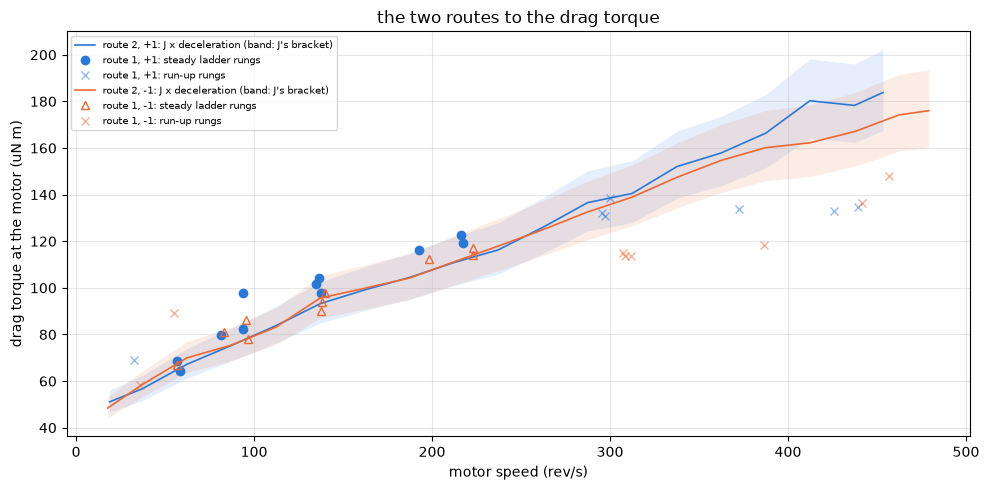

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
for d, c in ((1, BLUE), (-1, ORANGE)):
    g = RB[RB["dir"] == d]
    ax.fill_between(g["rev_s"], g["T_lo_uNm"], g["T_hi_uNm"], color=c,
                    alpha=0.12, lw=0)
    ax.plot(g["rev_s"], g["T_uNm"], color=c, lw=1.2,
            label=f"route 2, {d:+d}: J x deceleration (band: J's bracket)")
    r = R[R["dir"] == d]
    ax.plot(r[r.tier <= 2]["rev_s"], r[r.tier <= 2]["T_uNm"], ms=6,
            **figures.direction_style(d, c),
            label=f"route 1, {d:+d}: steady ladder rungs")
    ax.plot(r[r.tier == 3]["rev_s"], r[r.tier == 3]["T_uNm"], "x",
            color=c, alpha=0.5, label=f"route 1, {d:+d}: run-up rungs")
figures.label(ax, x="motor speed (rev/s)",
              y="drag torque at the motor (uN m)",
              title="the two routes to the drag torque")
ax.legend(fontsize=7)
figures.finish(fig)

What you are looking at. Both routes against speed, route 2 the run-up coasts through J with J's bracket shaded, route 1 the steady ladder rungs and, as crosses, its run-up rungs. Up to 223 rev/s the rungs sit on or just above the coast curve. Over 290 rev/s the run-up rungs sit under it, the settled-equivalent's bias on a spin still accelerating (discrepancy 4), so above 230 rev/s only route 2 reads the drag.

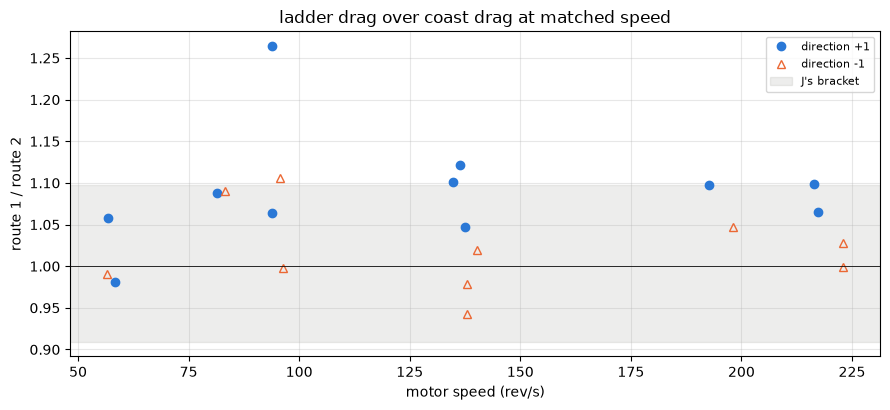

In [41]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for d, c in ((1, BLUE), (-1, ORANGE)):
    g = M[M["dir"] == d]
    ax.plot(g["rev_s"], g["ratio_run"], ms=6,
            **figures.direction_style(d, c), label=f"direction {d:+d}")
ax.axhline(1, color=INK, lw=0.6)
ax.axhspan(J / J_HI, J / J_LO, color=MUTED, alpha=0.15,
           label="J's bracket")
figures.label(ax, x="motor speed (rev/s)", y="route 1 / route 2",
              title="ladder drag over coast drag at matched speed")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. Route 1 over route 2 per steady rung against speed, per direction, with J's bracket shaded. The ratios scatter about 1 with no trend in speed, the +1 rungs above the -1 rungs on average.

## 7. The bare motor and the train's share

mg90-d's motor was never run bare. The type's two bare motors from stage 2, mg90-b and mg90-c, give the drag a motor of this type has with no train, read under drive with a meter in the loop so the reading term is out, and on their free coasts times their own J. The servo's drag less the type's is the train's share, a comparison with caveats.

In [42]:
def type_drive_T(m, w_rev_s):
    """A type motor's 5 V drive drag, N m, inside its measured range:
    I0 = a + b ln(w / 100 rev/s) with the reading term out, times Kt."""
    e = TYPE_NL[m]["drive_drag_by_level_meter"]["5 V"]
    kt = TYPE_NL[m]["kt_n_m_per_a"]["value"]
    w = np.asarray(w_rev_s, float)
    i0 = e["a_a"]["value"] + e["b_a"]["value"] * np.log(w * RPS
                                                        / (RPS * 100))
    rng = e["speed_range_rev_s"]
    return np.where((w >= rng["lo"]) & (w <= rng["hi"]), i0 * kt, np.nan)


def type_coast_T(m, w_rev_s):
    """A type motor's late coast, (a + b sqrt(w)) times its own J, N m."""
    e = TYPE_NL[m]["coast_decel_late_rad_s2"]
    w = np.asarray(w_rev_s, float)
    a = e["a"]["value"] + e["b"]["value"] * np.sqrt(w * RPS)
    rng = e["speed_range_rev_s"]
    return np.where((w >= rng["lo"]) & (w <= rng["hi"]),
                    a * TYPE_NL[m]["j_kg_m2"]["value"], np.nan)


for m in TYPE_NL:
    e = TYPE_NL[m]["drive_drag_by_level_meter"]["5 V"]
    print(f"{m}: Kt {TYPE_NL[m]['kt_n_m_per_a']['value'] * 1e3:.4f} mN m/A"
          f"; drive I0 {e['a_a']['value'] * 1e3:.1f} + "
          f"{e['b_a']['value'] * 1e3:.1f} ln(w / 100) mA over "
          f"{e['speed_range_rev_s']['lo']:.0f} to "
          f"{e['speed_range_rev_s']['hi']:.0f} rev/s")

mg90-b: Kt 1.1684 mN m/A; drive I0 53.1 + 21.5 ln(w / 100) mA over 64 to 338 rev/s
mg90-c: Kt 1.1652 mN m/A; drive I0 47.4 + 22.0 ln(w / 100) mA over 67 to 342 rev/s


In [43]:
W_SHARE = np.array([60, 80, 100, 150, 200, 250, 300, 340, 400, 460])
rows = []
for w in W_SHARE:
    r = {"rev_s": w}
    for d in (1, -1):
        r[f"servo_r2_{d:+d}"] = route2_at(d, w)
    r["servo_r2_mean"] = np.mean([r["servo_r2_+1"], r["servo_r2_-1"]])
    for m in TYPE_NL:
        r[f"{m}_drive"] = u_nm(type_drive_T(m, w))
        r[f"{m}_coast"] = u_nm(type_coast_T(m, w))
    both = [x for x in (r["mg90-b_drive"], r["mg90-c_drive"])
            if np.isfinite(x)]
    r["bare_mean"] = np.mean(both) if both else np.nan
    r["share_uNm"] = r["servo_r2_mean"] - r["bare_mean"]
    r["share_ma"] = ma_at_kt(r["share_uNm"] * 1e-6)
    r["share_frac"] = r["share_uNm"] / r["servo_r2_mean"]
    rows.append(r)
SHARE = pd.DataFrame(rows)
show(SHARE, n=None)
for _, r in SHARE.dropna(subset=["share_uNm"]).iterrows():
    print(f"{r['rev_s']:.0f} rev/s: servo {r['servo_r2_mean']:.1f}, bare "
          f"{r['bare_mean']:.1f}, the train {r['share_uNm']:.1f} uN m = "
          f"{r['share_ma']:.1f} mA, {r['share_frac']:.3f} of the servo's")

,rev_s,servo_r2_+1,servo_r2_-1,servo_r2_mean,mg90-b_drive,mg90-b_coast,mg90-c_drive,mg90-c_coast,bare_mean,share_uNm,share_ma,share_frac
0,60,66.256,68.932,67.594,NaN,51.719,NaN,44.880,NaN,NaN,NaN,NaN
1,80,72.947,73.852,73.400,56.489,56.562,49.527,49.815,53.008,20.392,17.593,0.278
2,100,79.606,79.360,79.483,62.098,60.829,55.250,54.162,58.674,20.809,17.953,0.262
3,150,96.251,97.770,97.011,72.289,69.912,65.649,63.418,68.969,28.042,24.193,0.289
4,200,107.701,107.726,107.714,79.521,77.569,73.027,71.220,76.274,31.440,27.125,0.292
5,250,121.223,121.503,121.363,85.130,84.315,78.750,78.095,81.940,39.424,34.012,0.325
6,300,138.546,135.757,137.151,89.712,90.414,83.425,84.310,86.569,50.582,43.639,0.369
7,340,152.590,148.113,150.351,NaN,94.935,86.635,88.916,86.635,63.716,54.970,0.424
8,400,173.378,161.196,167.287,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,460,183.822,173.514,178.668,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


80 rev/s: servo 73.4, bare 53.0, the train 20.4 uN m = 17.6 mA, 0.278 of the servo's
100 rev/s: servo 79.5, bare 58.7, the train 20.8 uN m = 18.0 mA, 0.262 of the servo's
150 rev/s: servo 97.0, bare 69.0, the train 28.0 uN m = 24.2 mA, 0.289 of the servo's
200 rev/s: servo 107.7, bare 76.3, the train 31.4 uN m = 27.1 mA, 0.292 of the servo's
250 rev/s: servo 121.4, bare 81.9, the train 39.4 uN m = 34.0 mA, 0.325 of the servo's
300 rev/s: servo 137.2, bare 86.6, the train 50.6 uN m = 43.6 mA, 0.369 of the servo's
340 rev/s: servo 150.4, bare 86.6, the train 63.7 uN m = 55.0 mA, 0.424 of the servo's


In [44]:
TYPE_PAIRS, SHARE_PAIRS = {}, {}
ww = np.linspace(70, 225, 40)            # the servo's fitted range
for m in TYPE_NL:
    Tm = u_nm(type_drive_T(m, ww))
    b, tc = np.polyfit(ww * RPS, Tm, 1)  # the log curve bent onto a line
    TYPE_PAIRS[m] = (tc, b)
    SHARE_PAIRS[m] = (pc[0] - tc, pc[1] - b)
    print(f"{m} as a line over 70 to 225 rev/s: Tc {tc:.1f} uN m, b "
          f"{b:.4f} uN m s/rad; the train against it: Coulomb "
          f"{pc[0] - tc:+.1f} uN m ({ma_at_kt((pc[0] - tc) * 1e-6):+.1f} mA),"
          f" viscous {pc[1] - b:+.4f} ({(pc[1] - b) / pc[1]:.0%} of b)")
S = SHARE.set_index("rev_s")
print(f"the type motors at 100 rev/s differ by "
      f"{abs(S.loc[100, 'mg90-b_drive'] - S.loc[100, 'mg90-c_drive']):.1f}"
      f" uN m")
for m in TYPE_NL:
    gap = [S.loc[w, m + "_coast"] - S.loc[w, m + "_drive"]
           for w in (100, 300)]
    print(f"{m}: coast x J less drive {gap[0]:+.1f} at 100 rev/s, "
          f"{gap[1]:+.1f} at 300 (uN m)")

mg90-b as a line over 70 to 225 rev/s: Tc 43.7 uN m, b 0.0289 uN m s/rad; the train against it: Coulomb +11.3 uN m (+9.8 mA), viscous +0.0184 (39% of b)
mg90-c as a line over 70 to 225 rev/s: Tc 36.5 uN m, b 0.0295 uN m s/rad; the train against it: Coulomb +18.6 uN m (+16.0 mA), viscous +0.0178 (38% of b)
the type motors at 100 rev/s differ by 6.8 uN m
mg90-b: coast x J less drive -1.3 at 100 rev/s, +0.7 at 300 (uN m)
mg90-c: coast x J less drive -1.1 at 100 rev/s, +0.9 at 300 (uN m)


The type's drive drag at 5 V is 53.1 + 21.5 ln(w / 100) mA on mg90-b and 47.4 + 22.0 ln(w / 100) mA on mg90-c, w in rev/s. Their coasts times their own J agree with it within 1.3 uN m at 100 and 300 rev/s. Against the servo's route 2, both directions' mean, the train adds 20.8 uN m (18.0 mA) at 100 rev/s, 31.4 (27.1 mA) at 200, 50.6 (43.6 mA) at 300 and 63.7 (55.0 mA) at 340, a share that grows from 0.262 to 0.424 of the servo's drag.

As a pair, with the type's curve bent onto a line over 70 to 225 rev/s, the train adds +11.3 uN m (against mg90-b) to +18.6 uN m (against mg90-c) of Coulomb drag and +0.0184 and +0.0178 uN m s/rad of viscous drag, 39 and 38 % of the servo's b. The type motor's own line carries the rest of the servo's b.

The caveats. mg90-d's motor was never run bare, so the type stands in for it. The two type motors differ by 6.8 uN m at 100 rev/s, the floor of this subtraction. The servo's numbers come from grease that is still running in (section 5). Low to moderate confidence on the share, moderate on its growth with speed.

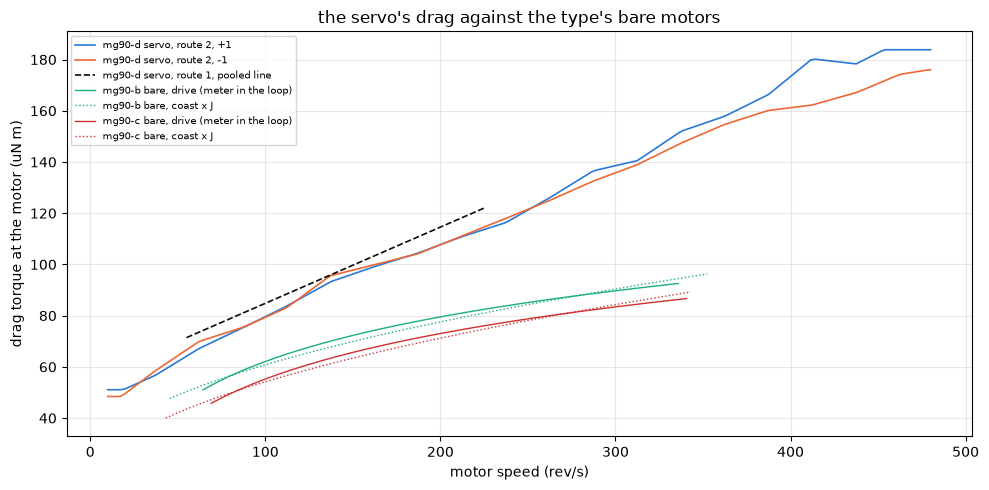

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))
ww = np.linspace(10, 480, 200)
for d, c in ((1, BLUE), (-1, ORANGE)):
    ax.plot(ww, route2_at(d, ww), color=c, lw=1.2,
            label=f"mg90-d servo, route 2, {d:+d}")
w1 = np.linspace(55, 225, 50)
ax.plot(w1, u_nm(drag_route1(w1)), color=INK, ls="dashed", lw=1.2,
        label="mg90-d servo, route 1, pooled line")
for m, c in (("mg90-b", GREEN), ("mg90-c", RED)):
    ax.plot(ww, u_nm(type_drive_T(m, ww)), color=c, lw=1,
            label=f"{m} bare, drive (meter in the loop)")
    ax.plot(ww, u_nm(type_coast_T(m, ww)), ":", color=c, lw=1,
            label=f"{m} bare, coast x J")
figures.label(ax, x="motor speed (rev/s)",
              y="drag torque at the motor (uN m)",
              title="the servo's drag against the type's bare motors")
ax.legend(fontsize=7)
figures.finish(fig)

What you are looking at. The servo's drag by route 2 per direction and route 1's pooled line, against the type's bare motors under drive (solid) and on their coasts times J (dotted). The servo sits above the bare motors everywhere they were read, and the gap widens with speed.

## 8. The static friction on one scale

The running drag is one number per speed. The static friction, or stiction, is the torque that holds a still rotor or a still output in place. This data bounds it from both ends of the train, and every reading below is at the motor, in uN m and in mA at Ke.

### The low holds

`ladder/low-1` kicks the rotor at about 1.5 V effective, then holds a lower duty and coasts, at levels over the three rails. A hold that stopped and never restarted sat under the stiction, so its winding current is a lower bound on it. The slowest holds that kept turning give the running friction at the floor.

In [46]:
HOLD_TAIL_S = 0.4                       # s, the hold's last stretch read


def hold_row(df, d, segs, zero_i, zero_e, rail):
    """One low hold: did it turn (the pot over 1 rev/s and the coast's
    early EMF over 1 rev/s), and its currents under construction C."""
    hold, cst = df[df.seg == segs[1]], df[df.seg == segs[2]]
    tail = hold.iloc[-int(HOLD_TAIL_S * FS):]
    half = float(tail["duty_counts"].abs().median())
    D = half / ARR
    pot_rps = abs(pot_slope_rev_s(tail["pos"]))
    emf = coast.emf_from_cut(cst, d, coast.cut_row(cst), zero_e,
                             v_per_count=SC.v_per_count)
    w_emf = coast.early_emf(emf) / KE / RPS
    row = {"dir": d, "rail_v": rail, "D": D, "v_eff_v": rail * D,
           "window_valid": float(tail["window_valid"].mean()),
           "pot_rev_s": pot_rps, "turning": bool(pot_rps > 1 and w_emf > 1),
           "pos_range": int(tail["pos"].max() - tail["pos"].min())}
    if row["window_valid"] > 0.99:
        i_a = crest_amps(tail["current_raw"].to_numpy(float), zero_i,
                         OFFSET)
        taps = ((tail["vmotor_a"] - tail["vmotor_b"]) * d).to_numpy(float)
        v_on = float(SC.volts(taps, SC.terminal_offset_counts).mean())
        _, i_c, v_c = construction_c(half, rail, v_on, float(i_a.mean()))
        row.update(i_crest_ma=i_a.mean() * 1e3, i_c_ma=float(i_c) * 1e3,
                   v_c_v=float(v_c), g_term_ma=G_S * (1 - D) * v_on * 1e3)
    return row

In [47]:
MOVE_COUNTS = 3                         # counts off the seat: it moved


def kick_row(kick, zero_i):
    """The kick's breakaway: the first row 3 counts off the seat, timed
    from the drive's first row, and the 5-row current peak until then."""
    k0 = tel.drive_start(kick)
    kk = kick.iloc[k0:]
    pos0 = (float(kick["pos"].iloc[max(0, k0 - 20):k0].median()) if k0 >= 1
            else float(kk["pos"].iloc[0]))
    moved = np.flatnonzero((kk["pos"] - pos0).abs().to_numpy()
                           > MOVE_COUNTS)
    if not len(moved):
        return {}
    t_b = moved[0]
    i_k = crest_amps(kk["current_raw"].to_numpy(float), zero_i, OFFSET)
    box = (np.convolve(i_k[:t_b + 1], np.ones(5) / 5, mode="valid")
           if t_b >= 4 else i_k[:t_b + 1])
    return {"kick_break_ms": t_b / FS * 1e3,
            "kick_i_peak_ma": float(box.max() * 1e3),
            "kick_D": float(kk["duty_counts"].abs().median()) / ARR}

In [48]:
cy = cycles.load(PAIR_DIR / "ladder" / "low-1")
rows = []
for _, r in cy.iterrows():
    folder = cy.folder(r["k"])
    df, zero_i, zero_e = load_sweep(folder)
    rail = float(probe_for(folder)["rail_v"])
    # each direction a kick, a hold and a coast: segments 1-3, then 4-6
    for d, segs in ((1, (1, 2, 3)), (-1, (4, 5, 6))):
        row = hold_row(df, d, segs, zero_i, zero_e, rail)
        row.update(k=int(r["k"]), volts_set=float(r["volts_set"]),
                   duty_set=int(r["duty_pct"]))
        if d == 1:
            row.update(kick_row(df[df.seg == segs[0]], zero_i))
            row["kick_v_eff"] = rail * row.get("kick_D", np.nan)
        rows.append(row)
HOLDS = pd.DataFrame(rows)
HOLDS["pot_turning"] = HOLDS["pot_rev_s"].where(HOLDS["turning"])
HOLDS["pos_stopped"] = HOLDS["pos_range"].where(~HOLDS["turning"])
LEVELS = HOLDS.groupby(["volts_set", "duty_set"]).agg(
    v_eff=("v_eff_v", "mean"), holds=("k", "size"),
    turned=("turning", "sum"), wv=("window_valid", "mean"),
    i_crest_ma=("i_crest_ma", "mean"), i_c_ma=("i_c_ma", "mean"),
    g_term_ma=("g_term_ma", "mean"), v_c_v=("v_c_v", "mean"),
    pot_rev_s=("pot_turning", "mean"),
    pos_range_stopped=("pos_stopped", "max")).reset_index()
LEVELS = LEVELS.sort_values("v_eff")
show(LEVELS, n=None)

,volts_set,duty_set,v_eff,holds,turned,wv,i_crest_ma,i_c_ma,g_term_ma,v_c_v,pot_rev_s,pos_range_stopped
0,3.700,5,0.184,6,0,0.000,NaN,NaN,NaN,NaN,NaN,7.000
6,5.000,4,0.200,6,0,0.000,NaN,NaN,NaN,NaN,NaN,7.000
12,7.400,3,0.222,6,0,0.000,NaN,NaN,NaN,NaN,NaN,11.000
7,5.000,5,0.249,6,0,0.000,NaN,NaN,NaN,NaN,NaN,8.000
1,3.700,7,0.258,6,0,1.000,58.786,42.766,16.020,0.206,NaN,11.000
2,3.700,8,0.295,6,1,1.000,64.961,49.113,15.847,0.240,14.114,8.000
13,7.400,4,0.296,6,0,0.000,NaN,NaN,NaN,NaN,NaN,8.000
8,5.000,6,0.300,6,0,1.000,71.594,51.385,20.209,0.210,NaN,7.000
14,7.400,5,0.369,6,5,0.000,NaN,NaN,NaN,NaN,16.041,4.000
9,5.000,8,0.399,6,6,1.000,60.003,38.512,21.491,0.332,19.964,NaN


Each level by its effective volts, rail times duty, with the holds that turned, the window's validity and the currents.

In [49]:
valid = HOLDS["window_valid"] > 0.99
STOPPED = HOLDS[~HOLDS["turning"] & valid]
TURNING = HOLDS[HOLDS["turning"] & valid]
C_RATIO = STOPPED["i_c_ma"] / 1e3 / ((STOPPED["v_c_v"] - V0_C) / R_C)
print(f"stopped holds with a valid window: n {len(STOPPED)}; i_c over "
      f"(V_c - V0) / R_C {C_RATIO.mean():.3f} sd {C_RATIO.std():.3f}")
never = LEVELS[LEVELS["turned"] == 0]
HI_NEVER = never.loc[never["v_eff"].idxmax()]
LO_ALWAYS = LEVELS[LEVELS["turned"] == LEVELS["holds"]].iloc[0]
STICK_C = HI_NEVER["i_c_ma"]             # mA, the C current there
STICK_R = (HI_NEVER["v_c_v"] - V0_C) / R_C * 1e3   # mA, V_c / R_C
print(f"highest level that never restarted: {HI_NEVER['v_eff']:.3f} V "
      f"eff ({HI_NEVER['volts_set']:g} V {HI_NEVER['duty_set']:.0f} %, "
      f"{HI_NEVER['turned']:.0f} of {HI_NEVER['holds']:.0f}), i_c "
      f"{STICK_C:.1f} mA, V_c / R_C {STICK_R:.1f} mA, crest "
      f"{HI_NEVER['i_crest_ma']:.1f} mA")
print(f"  = {u_nm(KT * STICK_C * 1e-3):.1f} and "
      f"{u_nm(KT * STICK_R * 1e-3):.1f} uN m at the motor")
print(f"lowest level that always turned: {LO_ALWAYS['v_eff']:.3f} V eff "
      f"({LO_ALWAYS['volts_set']:g} V {LO_ALWAYS['duty_set']:.0f} %), i_c "
      f"{LO_ALWAYS['i_c_ma']:.1f} mA at {LO_ALWAYS['pot_rev_s']:.1f} rev/s")
x = LEVELS[(LEVELS["volts_set"] == 7.4) & (LEVELS["duty_set"] == 5)]
print(f"7.4 V 5 %: {x['v_eff'].iloc[0]:.3f} V eff, "
      f"{x['turned'].iloc[0]:.0f} of {x['holds'].iloc[0]} turned")

stopped holds with a valid window: n 17; i_c over (V_c - V0) / R_C 1.096 sd 0.083
highest level that never restarted: 0.300 V eff (5 V 6 %, 0 of 6), i_c 51.4 mA, V_c / R_C 42.7 mA, crest 71.6 mA
  = 59.6 and 49.5 uN m at the motor
lowest level that always turned: 0.399 V eff (5 V 8 %), i_c 38.5 mA at 20.0 rev/s
7.4 V 5 %: 0.369 V eff, 5 of 6 turned


In [50]:
SLOW = TURNING[TURNING["pot_rev_s"] < 30]   # the slowest turning holds
w_floor = SLOW["pot_rev_s"].mean()
print(f"turning holds under 30 rev/s: n {len(SLOW)}, {w_floor:.1f} sd "
      f"{SLOW['pot_rev_s'].std():.1f} rev/s, i_c {SLOW['i_c_ma'].mean():.1f}"
      f" sd {SLOW['i_c_ma'].std():.1f} mA, crest "
      f"{SLOW['i_crest_ma'].mean():.1f} mA; "
      f"{u_nm(KT * SLOW['i_c_ma'].mean() * 1e-3):.1f} uN m")
print("route 1's line there: " + ", ".join(
    f"{d:+d} {ma_at_kt(drag_route1(w_floor, d)):.1f} mA" for d in (1, -1))
      + f"; route 2's lowest bin: "
      f"{ma_at_kt(np.mean([route2_at(d, 12) for d in (1, -1)]) * 1e-6):.1f}"
      f" mA")
KICKS = HOLDS.dropna(subset=["kick_break_ms"])
print(f"the kick, +1 at {KICKS['kick_v_eff'].mean():.2f} V eff, n "
      f"{len(KICKS)}: the pot left "
      f"its seat {KICKS['kick_break_ms'].mean():.1f} sd "
      f"{KICKS['kick_break_ms'].std():.1f} ms in, at a current peak of "
      f"{KICKS['kick_i_peak_ma'].mean():.0f} sd "
      f"{KICKS['kick_i_peak_ma'].std():.0f} mA (the ladder result: "
      f"{LADDER['kick_breakaway_ms_fwd']['value']:.1f} ms, "
      f"{LADDER['kick_current_at_move_a']['value'] * 1e3:.0f} mA)")

turning holds under 30 rev/s: n 15, 22.0 sd 4.3 rev/s, i_c 39.2 sd 4.8 mA, crest 57.4 mA; 45.4 uN m
route 1's line there: +1 52.9 mA, -1 52.7 mA; route 2's lowest bin: 42.9 mA
the kick, +1 at 1.48 V eff, n 51: the pot left its seat 9.2 sd 1.9 ms in, at a current peak of 311 sd 24 mA (the ladder result: 9.4 ms, 313 mA)


The highest level that never restarted is 0.300 V effective, 5 V at 6 %, 0 of 6 holds turned. Its C current is 51.4 mA and its V_c / R_C 42.7 mA, crest 71.6 mA, so the stiction driven from the motor is at least 49.5 to 59.6 uN m, high confidence as a bound. Its value is low to moderate, since g and the edge share at 6 % duty are extrapolated. At 0.399 V, 5 V at 8 %, every hold turned, at 20.0 rev/s on 38.5 mA, and at 7.4 V 5 %, 0.369 V, 5 of 6 turned.

The 17 stopped holds with a valid window draw 1.096 sd 0.083 of the current construction C's line predicts from their volts, (V_c - V0) / R_C. At these duties construction C does not close, likely, with g and the edge share both read outside the bands they were measured over (discrepancy 3).

The 15 turning holds under 30 rev/s run at 22.0 sd 4.3 rev/s on 39.2 sd 4.8 mA under C, 57.4 crest, 45.4 uN m. Route 1's line gives 52.9 mA at that speed and route 2's lowest bin 42.9 mA. Every kick moved, at 1.48 V effective, the pot leaving its seat 9.2 sd 1.9 ms in at a current peak of 311 sd 24 mA over 51 kicks, against the ladder result's 9.4 ms and 313 mA. A kick bounds the breakaway only from above.

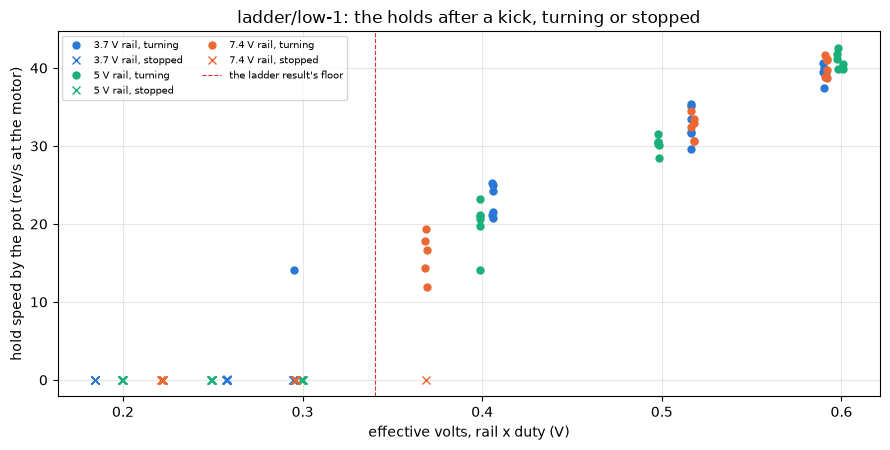

In [51]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for v, c in RAIL_COLOR.items():
    g = HOLDS[HOLDS["volts_set"] == v]
    t, s = g[g["turning"]], g[~g["turning"]]
    ax.plot(t["v_eff_v"], t["pot_rev_s"], "o", color=c, ms=5,
            label=f"{v:g} V rail, turning")
    ax.plot(s["v_eff_v"], s["pot_rev_s"], "x", color=c, ms=6,
            label=f"{v:g} V rail, stopped")
ax.axvline(LADDER["floor_v_effective"]["value"], **figures.HIGHLIGHT_STYLE,
           label="the ladder result's floor")
figures.label(ax, x="effective volts, rail x duty (V)",
              y="hold speed by the pot (rev/s at the motor)",
              title="ladder/low-1: the holds after a kick, turning or "
              "stopped")
ax.legend(fontsize=7, ncol=2)
figures.finish(fig)

What you are looking at. Each hold's speed by the pot against its effective volts, dots for the holds that turned and crosses for those that stopped, one color per rail, the ladder result's floor dashed. The boundary between stopping and turning is a band in effective volts shared by the three rails, with one turning hold just under the floor and one stopped hold above it. The holds either stop or turn well clear of zero speed, and none crawls.

### The take-up at a start

The free steps' 20 % starts from rest. The current through J, with route 1's drag taken off, gives how far the rotor turns before the pot moves 3 counts, the reference read 1 to 2 ms in, past the pot's current-coupled shift at a -1 start. If the drag mattered here, the travel would move with the drag model.

In [52]:
TAKEUP_S = 0.06                         # s, the start read
REF_ROWS = slice(20, 40)                # 1 to 2 ms in, the pot's reference


def travel(i_w, t_mv, drag):
    """Rotor turns until row t_mv: Kt i_w less the drag through J, the
    drag never driving the rotor backward from rest."""
    w = th = 0.0
    for j in range(t_mv):
        T_m = KT * i_w[j]
        T_d = drag(np.array([w]))[0]
        T = (T_m - T_d if w > 0 or T_m > drag(np.array([0.0]))[0]
             else 0.0)
        w = max(0.0, w + T / J / FS)
        th += w / FS
    return th / RPS, w / RPS

In [53]:
ch = cycles.load(PAIR_DIR / "steps" / "capture-1", table="chains.csv")
rows = []
for _, r in ch[ch["base_pct"] == 20].iterrows():
    df, zero_i, _ = load_sweep(ch.folder(r["k"]))
    for d, seg in ((1, 1), (-1, 4)):
        s = df[df.seg == seg]
        dr = s.iloc[tel.drive_start(s):][:int(TAKEUP_S * FS)]
        D = float(dr["duty_counts"].abs().median()) / ARR
        i_a = crest_amps(dr["current_raw"].to_numpy(float), zero_i, OFFSET)
        v_on = SC.volts(((dr["vmotor_a"] - dr["vmotor_b"]) * d)
                        .to_numpy(float), SC.terminal_offset_counts)
        i_w = i_a - G_S * (1 - D) * v_on
        pos = dr["pos"].to_numpy(float)
        pos0 = float(np.median(pos[REF_ROWS]))
        mv = np.flatnonzero(np.abs(pos[REF_ROWS.stop:] - pos0) > MOVE_COUNTS)
        if not len(mv):
            continue
        t_mv = int(mv[0]) + REF_ROWS.stop
        out = {"k": int(r["k"]), "dir": d, "t_move_ms": t_mv / FS * 1e3}
        tc = CARRIED[d]["coef"][0] * 1e-6
        for lab, drag in (("route1", lambda w: drag_route1(w / RPS, d)),
                          ("coulomb", lambda w: tc * np.ones_like(w)),
                          ("no_drag", lambda w: 0.0 * w)):
            out[f"turns_{lab}"], _ = travel(i_w, t_mv, drag)
        rows.append(out)
TAKE = pd.DataFrame(rows)

In [54]:
TAKE_AGG = TAKE.groupby("dir").agg(
    n=("k", "size"), t_move_ms=("t_move_ms", "mean"),
    t_sd=("t_move_ms", "std"), turns_route1=("turns_route1", "mean"),
    turns_route1_sd=("turns_route1", "std"),
    turns_coulomb=("turns_coulomb", "mean"),
    turns_no_drag=("turns_no_drag", "mean"))
for d, r in TAKE_AGG.iterrows():
    print(f"{d:+d} (n {r['n']:.0f}): the pot moves {r['t_move_ms']:.1f} sd "
          f"{r['t_sd']:.1f} ms in; rotor turns with route 1's drag "
          f"{r['turns_route1']:.3f} sd {r['turns_route1_sd']:.3f}, Coulomb "
          f"only {r['turns_coulomb']:.3f}, no drag {r['turns_no_drag']:.3f}")
lever = TAKE_AGG["turns_no_drag"] - TAKE_AGG["turns_route1"]
print("the drag's lever on the travel, no drag less route 1: " + ", ".join(
    f"{d:+d} {x:.3f} turns" for d, x in lever.items()))
st = FREE_STEPS
print(f"the steps result's play from rest: +1 "
      f"{st['play_from_rest_turns_dir_pos']['value']:.3f}, -1 "
      f"{st['play_from_rest_turns_dir_neg']['value']:.3f} turns; "
      f"reversals at 10 / 20 / 30 %: " + " / ".join(
          f"{st[f'reversal_{p}_play_turns']['value']:.2f}"
          for p in (10, 20, 30)) + " turns")
LASH_TURNS = {"motion": POT["lash_deg"]["value"] * GEAR / 360,
              "hand": POT["lash_hand_deg"]["value"] * GEAR / 360}
print(f"the pot table's lash: in motion {POT['lash_deg']['value']:.2f} deg"
      f" = {LASH_TURNS['motion']:.2f} motor turns, by hand "
      f"{POT['lash_hand_deg']['value']:.2f} deg = "
      f"{LASH_TURNS['hand']:.2f} turns")

-1 (n 9): the pot moves 5.3 sd 1.5 ms in; rotor turns with route 1's drag 0.055 sd 0.033, Coulomb only 0.056, no drag 0.077
+1 (n 9): the pot moves 10.6 sd 2.3 ms in; rotor turns with route 1's drag 0.198 sd 0.076, Coulomb only 0.204, no drag 0.283
the drag's lever on the travel, no drag less route 1: -1 0.021 turns, +1 0.085 turns
the steps result's play from rest: +1 0.230, -1 0.024 turns; reversals at 10 / 20 / 30 %: 0.29 / 0.04 / -0.11 turns
the pot table's lash: in motion 0.39 deg = 0.33 motor turns, by hand 1.24 deg = 1.06 turns


The +1 starts turn the rotor 0.198 sd 0.076 turns before the pot moves, 10.6 sd 2.3 ms in, and the -1 starts 0.055 sd 0.033 turns at 5.3 sd 1.5 ms, 9 starts each way. With no drag the same currents give 0.283 and 0.077 turns, with the Coulomb term alone 0.204 and 0.056. The steps result read 0.230 and 0.024 turns by its own route, the pot table's lash is 0.33 motor turns in motion and 1.06 by hand, and the reversals' play reads 0.29, 0.04 and -0.11 turns, one pair each. The drag moves the implied travel by 0.021 and 0.085 turns, so the take-up reads the lash and the train's wind-up after the seek, and it is a weak lever on the friction.

### The hanging arm's bounds

The load result reads the back-driven train. Its 12 % rests held the arm through a coast with the bridge open, 6 of 6, and its falls start against the release friction, gravity less J alpha over each fall's first 80 ms, with alpha the angular acceleration. Its sittings 2 and 3 measure the static holding friction from the events that held or released with the motor near zero (the load notebook's section 11.7), and the hold's deadband from duty steps (its section 11.4). All are output torques, here divided by N with no loss.

In [55]:
def at_motor(mn_m):
    """An output torque in mN m at the motor, lossless: uN m and mA."""
    return mn_m / GEAR * 1e3, mn_m / GEAR / KT


HELD_UNM, HELD_MA = at_motor(HELD["value"])
rest = LOAD["hold_rest_12pct_deg"]
print("the load result's 12 % rests: " + ", ".join(
    f"{s} {v['value']:.2f} deg" for s, v in rest.items()))
REL_UNM, REL_MA = at_motor(RELEASE["value"])
REL_SD_UNM = (RELEASE["hi"] - RELEASE["value"]) / GEAR * 1e3
print(f"held bound (the load result): >= {HELD['value']:.2f} mN m at the "
      f"output = {HELD_UNM:.1f} uN m = {HELD_MA:.1f} mA at the motor")
print(f"release: {RELEASE['value']:.2f} mN m (sd "
      f"{RELEASE['hi'] - RELEASE['value']:.2f}) = {REL_UNM:.1f} +/- "
      f"{REL_SD_UNM:.1f} uN m = {REL_MA:.1f} mA at the motor")
print(f"static friction, sittings 2 and 3: {STATIC['value']:.1f} "
      f"({STATIC['lo']:.0f} to {STATIC['hi']:.0f}) mN m at the output, "
      f"the most held {STATIC_HELD['value']:.1f}, the least released "
      f"{STATIC_FREE['value']:.1f}; {STATIC_UNM['value']:.0f} "
      f"({STATIC_UNM['lo']:.0f} to {STATIC_UNM['hi']:.0f}) uN m at the "
      f"motor; grows with load: {LOAD['static_friction_grows_with_load']}")
print(f"the hold's deadband, a ratchet: {LOAD['hold_is_a_ratchet']}, up "
      f"{DEADBAND['up']['lo']:.0f} to {DEADBAND['up']['hi']:.0f} %, down "
      f"{DEADBAND['down']['lo']:.0f} to {DEADBAND['down']['hi']:.0f} % "
      f"of duty")

the load result's 12 % rests: +1 9.52 deg, -1 9.51 deg
held bound (the load result): >= 16.65 mN m at the output = 54.0 uN m = 46.6 mA at the motor
release: 33.39 mN m (sd 4.67) = 108.4 +/- 15.2 uN m = 93.5 mA at the motor
static friction, sittings 2 and 3: 30.5 (25 to 36) mN m at the output, the most held 35.4, the least released 26.7; 99 (81 to 117) uN m at the motor; grows with load: not established
the hold's deadband, a ratchet: True, up 5 to 10 %, down 20 to 25 % of duty


In [56]:
tc2 = np.mean([LOW2[d]["coef"][0] for d in (1, -1)])
tc2_se = np.hypot(LOW2[1]["se"][0], LOW2[-1]["se"][0]) / 2
coast12 = np.mean([route2_at(d, 12) for d in (1, -1)])
floor_unm = u_nm(KT * SLOW["i_c_ma"] * 1e-3)
SCL = pd.DataFrame([
    ("running Coulomb, route 1 pooled", pc[0], ps[0], "running"),
    ("running Coulomb, route 2 under 230 rev/s", tc2, tc2_se, "running"),
    ("coast drag, lowest bin", coast12, 0.1 * coast12, "running"),
    ("running at the floor, low holds", floor_unm.mean(),
     floor_unm.std(), "running"),
    ("stopped hold at 0.300 V eff, C current",
     u_nm(KT * STICK_C * 1e-3), np.nan, "driven bound"),
    ("stopped hold at 0.300 V eff, V_c / R_C",
     u_nm(KT * STICK_R * 1e-3), np.nan, "driven bound"),
    ("load held bound", HELD_UNM, np.nan, "back-driven bound"),
    ("load release", REL_UNM, REL_SD_UNM, "back-driven"),
    # the bar its lo to hi, which sit symmetric about the value
    ("load static friction, sittings 2 and 3", STATIC_BAR[0],
     (STATIC_BAR[2] - STATIC_BAR[1]) / 2, "back-driven"),
    ("kick, every one moved", u_nm(KT * KICKS["kick_i_peak_ma"].mean()
                                   * 1e-3), np.nan, "upper bound")],
    columns=["reading", "uNm", "err", "kind"])
SCL["ma"] = ma_at_kt(SCL["uNm"] * 1e-6)
for _, r in SCL.iterrows():
    err = "" if np.isnan(r["err"]) else f" +/- {r['err']:.1f}"
    print(f"{r['reading']:42s} {r['uNm']:6.1f}{err} uN m, "
          f"{r['ma']:5.1f} mA ({r['kind']})")
RATIOS = {"driven_c": SCL.loc[4, "uNm"] / pc[0],
          "driven_r": SCL.loc[5, "uNm"] / pc[0],
          "held": HELD_UNM / pc[0], "release": REL_UNM / pc[0]}
MEASURED = tuple(v / pc[0] for v in STATIC_BAR)   # value, lo, hi
RATIOS["measured"] = MEASURED[0]
print("over the running Coulomb term (route 1 pooled): " + ", ".join(
    f"{k} {v:.2f}" for k, v in RATIOS.items())
      + f" ({MEASURED[1]:.2f} to {MEASURED[2]:.2f})")
slip = SLOW["i_c_ma"].mean()
print(f"the stopped hold's current over the floor's running current: "
      f"{STICK_R / slip:.2f} (V_c / R_C) to {STICK_C / slip:.2f} (C)")

running Coulomb, route 1 pooled              55.1 +/- 3.3 uN m,  47.5 mA (running)
running Coulomb, route 2 under 230 rev/s     47.6 +/- 1.2 uN m,  41.1 mA (running)
coast drag, lowest bin                       49.8 +/- 5.0 uN m,  42.9 mA (running)
running at the floor, low holds              45.4 +/- 5.5 uN m,  39.2 mA (running)
stopped hold at 0.300 V eff, C current       59.6 uN m,  51.4 mA (driven bound)
stopped hold at 0.300 V eff, V_c / R_C       49.5 uN m,  42.7 mA (driven bound)
load held bound                              54.0 uN m,  46.6 mA (back-driven bound)
load release                                108.4 +/- 15.2 uN m,  93.5 mA (back-driven)
load static friction, sittings 2 and 3       99.0 +/- 17.9 uN m,  85.4 mA (back-driven)
kick, every one moved                       360.6 uN m, 311.1 mA (upper bound)
over the running Coulomb term (route 1 pooled): driven_c 1.08, driven_r 0.90, held 0.98, release 1.97, measured 1.80 (1.47 to 2.12)
the stopped hold's current over the 

On one scale at the motor.

- Running. Route 1's Coulomb term is 55.1 +/- 3.3 uN m, 47.5 mA. Route 2's line under 230 rev/s gives 47.6 +/- 1.2 uN m and its lowest bin 49.8 uN m. The low holds' running friction at 22.0 rev/s is 45.4 +/- 5.5 uN m.
- Driven from the motor. The rotor held still under 49.5 to 59.6 uN m at 0.300 V effective and never restarted, a lower bound on the stiction, high confidence as a bound.
- Back-driven from the output. The static friction is measured, 30.5 (25 to 36) mN m at the output by the load notebook's section 11.7, from the events of sittings 2 and 3 that held or released with the motor near zero. At the motor that is 99 (81 to 117) uN m, 85.4 mA. Whether it grows with load is not established. Sitting 1's held bound, the arm at 9.52 and 9.51 degrees through the coast, 54.0 uN m, 46.6 mA, is superseded. Its falls' release at 108.4 +/- 15.2 uN m, 93.5 mA, is confirmed by a route without the lash.
- The kick at 311 mA moved every time, an upper bound far above the rest.

Over route 1's Coulomb term the driven bound is 0.90 to 1.08, sitting 1's back-driven held bound 0.98 and its release 1.97, and the measured static friction 1.80 (1.47 to 2.12). At the floor the stopped hold drew 1.09 to 1.31 of the current the slowest turning holds run on, so the stick sits above the slip by at least that, low to moderate confidence since g at these duties is extrapolated. Back-driven from the output, the stiction is measured at 1.47 to 2.12 times the running Coulomb term, where the falls' release put it. Driven from the motor it is bounded, at least about the running Coulomb term. The driven breakaway, between 0.300 V effective and the kick, is not measured. The measurement owed is a sweep of 300 ms pulses from rest at 0.3 to 1.0 V effective in 0.1 V steps, both directions, from three starts, the ladder result's open item. The load notebook measured the hold's deadband under the arm (its section 11.4). A duty hold is a ratchet, with a deadband of 5 to 10 % of duty up and 20 to 25 % down.

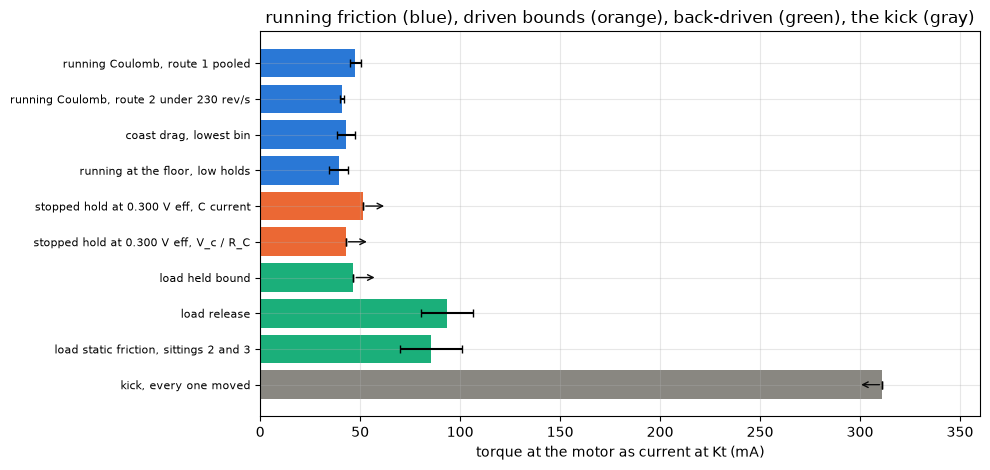

In [57]:
KIND_COLOR = {"running": BLUE, "driven bound": ORANGE,
              "back-driven bound": GREEN, "back-driven": GREEN,
              "upper bound": MUTED}
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(SCL))[::-1]
ax.barh(y, SCL["ma"], xerr=ma_at_kt(SCL["err"].fillna(0) * 1e-6),
        color=[KIND_COLOR[k] for k in SCL["kind"]], capsize=3)
for yy, (_, r) in zip(y, SCL.iterrows()):
    if "bound" in r["kind"]:
        ax.annotate("", xy=(r["ma"] + (12 if r["kind"] != "upper bound"
                                       else -12), yy), xytext=(r["ma"], yy),
                    arrowprops={"arrowstyle": "->", "color": INK})
ax.set_yticks(y)
ax.set_yticklabels(SCL["reading"], fontsize=8)
ax.set_xlim(0, 360)
figures.label(ax, x="torque at the motor as current at Kt (mA)",
              title="running friction (blue), driven bounds (orange), "
              "back-driven (green), the kick (gray)")
figures.finish(fig)

What you are looking at. Every reading of the running and the static friction as a current at Kt, blue the running drag, orange the bounds driven from the motor, green the back-driven readings and gray the kick. An arrow marks a bound and the way it points. The running drag and every lower bound sit in one band, and only the falls' release, the measured static friction and the kick sit above it.

## 9. The train's efficiency

The load result's stall lines give Kt through the gears at a rising stall, absolute with the arm weighed. Over the lossless Ke times N it is the train's torque efficiency at stall, eta, with N the gear ratio. Their intercepts are compared here with the motor's own Coulomb drag passed through the train, -eta N Tc.

In [58]:
KEN = KE * GEAR * 1e3                    # mN m/A at the output, lossless
ETA = {s: KT_GEAR[s]["value"] / KEN for s in ("+1", "-1", "pooled")}
STALL_PRED = {}
for s, d in (("+1", 1), ("-1", -1)):
    tc = CARRIED[d]["coef"][0] * 1e-6     # N m, route 1's Coulomb term
    pred = -ETA[s] * GEAR * tc * 1e3       # mN m, -eta N Tc
    ic = INTERCEPT[s]
    i0 = -ic["value"] / KT_GEAR[s]["value"] * 1e3   # mA at zero torque
    STALL_PRED[s] = (pred, i0)
    inside = ic["lo"] <= pred <= ic["hi"]
    off = min(abs(pred - ic["lo"]), abs(pred - ic["hi"]))
    where = ("inside the bracket" if inside
             else f"outside the bracket by {off:.2f}")
    print(f"{s}: Kt_gear {KT_GEAR[s]['value']:.1f} ({KT_GEAR[s]['lo']:.1f}"
          f" to {KT_GEAR[s]['hi']:.1f}) mN m/A, eta {ETA[s]:.3f}; intercept"
          f" {ic['value']:+.2f} ({ic['lo']:+.2f} to {ic['hi']:+.2f}) "
          f"against -eta N Tc {pred:+.2f} mN m, {where}; i0 {i0:.0f} mA "
          f"against Tc / Kt {ma_at_kt(tc):.0f} mA")
print(f"pooled: {KT_GEAR['pooled']['value']:.1f} mN m/A, eta "
      f"{ETA['pooled']:.3f}; Ke x N {KEN:.1f} mN m/A; side split "
      f"{LOAD['side_kt_gear_split_sigma']['all']['value']:.1f} sigma, "
      f"{LOAD['side_kt_gear_split_sigma']['table-only']['value']:.1f} "
      f"table-only (the load result)")
KT_ALL = LOAD["kt_gear_all_sittings_mn_m_per_a"]   # of record
ETA_ALL = LOAD["train_efficiency_all_sittings"]
SIDES = LOAD["side_split_bound_pct"]    # % down over up, below the edge
print(f"of record, three sittings: {KT_ALL['value']:.1f} ("
      f"{KT_ALL['lo']:.1f} to {KT_ALL['hi']:.1f}) mN m/A, eta "
      f"{ETA_ALL['value']:.3f} ({ETA_ALL['lo']:.3f} to "
      f"{ETA_ALL['hi']:.3f}); side split established "
      f"{LOAD['side_split_established']}, down over up {SIDES['lo']:.1f} "
      f"to {SIDES['hi']:.1f} % below "
      f"{LOAD['rest_dip_angle_deg']['lo']:.1f} deg")
STALL_M = RUNUP["stall_torque_n_m"]["value"]   # N m at the motor, 5 V
HORN = STALL_M * GEAR * ETA["pooled"] * 1e3
print(f"stall at the horn: {STALL_M * 1e3:.3f} mN m x N x "
      f"{ETA['pooled']:.3f} = {HORN:.0f} mN m (lossless "
      f"{STALL_M * GEAR * 1e3:.0f}; 1.8 kg cm = {1.8 * 9.80665 * 10:.0f})")

+1: Kt_gear 215.8 (210.7 to 220.0) mN m/A, eta 0.604; intercept -8.12 (-9.51 to -5.71) against -eta N Tc -10.11 mN m, outside the bracket by 0.60; i0 38 mA against Tc / Kt 47 mA
-1: Kt_gear 234.3 (228.1 to 242.7) mN m/A, eta 0.656; intercept -9.40 (-12.84 to -7.37) against -eta N Tc -11.12 mN m, inside the bracket; i0 40 mA against Tc / Kt 47 mA
pooled: 222.9 mN m/A, eta 0.624; Ke x N 357.1 mN m/A; side split 2.6 sigma, 1.6 table-only (the load result)
of record, three sittings: 225.7 (221.3 to 242.0) mN m/A, eta 0.632 (0.620 to 0.678); side split established False, down over up 4.5 to 19.8 % below 41.5 deg
stall at the horn: 1.046 mN m x N x 0.624 = 201 mN m (lossless 322; 1.8 kg cm = 177)


In the load result's sitting 1, Kt through the gears is 215.8 (210.7 to 220.0) mN m/A on the up side, +1, and 234.3 (228.1 to 242.7) on the down side, -1, 222.9 pooled, against Ke x N of 357.1. The efficiency at the rising stall is 0.604, 0.656 and 0.624. The side split there is 2.6 sigma with every rung and 1.6 table-only. Over the load result's three sittings Kt through the gears of record is one value for both directions, 225.7 (221.3 to 242.0) mN m/A, 0.632 (0.620 to 0.678) of Ke x N. The side split as a ratio is not established (the load notebook's section 11.3). As a bound, the down side reads 4.5 to 19.8 % over the up side below 41.5 degrees. The rest of this section reads sitting 1's lines.

The intercepts are -8.12 (-9.51 to -5.71) mN m up and -9.40 (-12.84 to -7.37) down. Route 1's Coulomb term through the efficiency, -eta N Tc, gives -10.11 and -11.12 mN m. The down side's prediction lies inside its bracket, and the up side's lies outside it by 0.60 mN m. The currents at zero torque, 38 and 40 mA, sit under the motor's Coulomb current of 47 mA. So the friction the rising arm sticks against is likely the motor's own running drag through the train, with no extra output-side term the data needs, moderate confidence. The up side's shortfall is a sitting 1 read. The load notebook's section 11.3 follows the sides over three sittings and leaves the offset by side open as its discrepancy 2.

At the rated point the run-up's stall torque at the motor, 1.046 mN m at 5 V, through N and the pooled 0.624 is 201 mN m at the horn, lossless 322, against the MG90's sold rating of 1.8 kg cm, 177 mN m.

### The lift at speed and the fall

The efficiency at speed needs the load notebook's lift rows, the motor's speed from the pot's slope and the winding current under construction C in windows of +/- 2 degrees about 10, 20 and 30 degrees. They are recomputed here from `load/lift-1` the way the load notebook reads them, through the pot table from the bottom of record. The gross efficiency is gravity's torque over N Kt i_w, with i_w the winding current. With route 1's free drag at that speed taken off the motor's torque, the rest is the efficiency on the load alone. The speed the load costs against the free 5 V rung at the same duty, both currents under construction C, is set against R_C di / Ke, with di the current the load adds.

In [59]:
TABLE = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                    .with_suffix(".table.csv"))
TC = TABLE["counts"].to_numpy()          # the table's counts, rising
TA = TABLE["angle_deg"].to_numpy()       # the tag degrees at each
S_LO = (TA[1] - TA[0]) / (TC[1] - TC[0])        # deg per count, low end
S_HI = (TA[-1] - TA[-2]) / (TC[-1] - TC[-2])    # deg per count, high end


def angle_of(counts):
    """Tag degrees of a pot count; past the ends the end slope runs on."""
    c = np.asarray(counts, float)
    a = np.interp(c, TC, TA)
    a = np.where(c < TC[0], TA[0] + (c - TC[0]) * S_LO, a)
    return np.where(c > TC[-1], TA[-1] + (c - TC[-1]) * S_HI, a)


def theta_deg(counts, bottom=BOTTOM):
    """Degrees from the bottom of record: + up the side of higher counts."""
    return angle_of(counts) - angle_of(bottom)


print(f"table {TC[0]:.0f} to {TC[-1]:.0f} counts; bottom {BOTTOM} counts")

table 582 to 3188 counts; bottom 2021 counts


In [60]:
def lift_sweep(folder):
    """The load notebook's sweep: amps over the zero with the in-drive
    offset out on driven rows, the crest tap volts, the EMF, the duty."""
    df, zero_i, zero_e = load_sweep(folder)
    driven = (df["duty_counts"] != 0).to_numpy()
    df["i_a"] = np.where(driven, SC.amps(df["current_raw"], zero_i, True),
                         SC.amps(df["current_raw"], zero_i, False))
    tap = df["vmotor_a"] - df["vmotor_b"]
    df["vdiff_v"] = SC.volts(tap, SC.terminal_offset_counts)
    df["emf_v"] = SC.volts(tap, zero_e)
    df["D"] = df["duty_counts"].abs() / ARR
    return df


def construction_c_5v(D, v_on, i_crest):
    """The load notebook's construction C: the edges measured at 5 V."""
    share = D - EDGE_5V / ARR
    c = scales.constructions(D, share, v_on, i_crest, share, share,
                             R_BRAKE, G_S)
    return c["i_c"]


def pot_speed(pos, half):
    """deg/s per row: a centered line through +/- half rows of angle."""
    a = angle_of(pos)
    k = np.arange(-half, half + 1)
    out = np.full(len(a), np.nan)
    for i in range(half, len(a) - half):
        out[i] = (k * (a[i - half:i + half + 1] - a[i])).sum()
    return out / (k ** 2).sum() * FS

In [61]:
LIFT_DIR = PAIR_DIR / "load" / "lift-1"
WIN_DEG, TAKE_UP_S, SPEED_HALF = 2.0, 0.03, 250   # the load notebook's
LIFT_CYCLES = pd.read_csv(LIFT_DIR / "cycles.csv")
lift_rows, FALLS = [], {}
for _, r in LIFT_CYCLES.iterrows():
    df = lift_sweep(LIFT_DIR / r["folder"])
    s1 = df[df["seg"] == 1].reset_index(drop=True)   # the drive
    s2 = df[df["seg"] == 2].reset_index(drop=True)   # the 3 s coast
    z = int(np.flatnonzero(s2["duty_counts"].to_numpy() == 0)[0]) + 2
    FALLS[r["k"]] = s2.iloc[z:].reset_index(drop=True)
    d = tel.drive_rows(s1).reset_index(drop=True)
    t = np.arange(len(d)) / FS
    th = np.abs(theta_deg(d["pos"]))
    w_m = pot_speed(d["pos"].to_numpy(), SPEED_HALF) / 360 * GEAR
    i_w = construction_c_5v(d["D"].to_numpy(),
                            np.abs(d["vdiff_v"].to_numpy()),
                            d["i_a"].to_numpy())
    out = {"k": r["k"], "side": r["side"], "duty_pct": r["duty_pct"],
           "repeat": r["repeat"]}
    for a0 in (10, 20, 30):
        m = ((th > a0 - WIN_DEG) & (th < a0 + WIN_DEG)
             & np.isfinite(w_m) & (t > TAKE_UP_S))
        ok = m.sum() > 50
        out[f"w_{a0}"] = abs(np.nanmean(w_m[m])) if ok else np.nan
        out[f"i_{a0}"] = np.nanmean(i_w[m]) if ok else np.nan
    lift_rows.append(out)
LIFT = pd.DataFrame(lift_rows)
ref = LOAD["lift_speed_at_10deg_rev_s"]
gap = [abs(r["w_10"] - ref[f"{int(r['side'] * r['duty_pct']):+d} % rep "
                          f"{int(r['repeat'])}"]["value"])
       for _, r in LIFT.iterrows()]
print(f"{len(LIFT)} lifts; speed at 10 deg against the load result's: "
      f"largest difference {max(gap):.2e} rev/s")

12 lifts; speed at 10 deg against the load result's: largest difference 0.00e+00 rev/s


In [62]:
FREE = {(int(r.duty_set), int(r.dir)): (r.rev_s, r.i_c_ma)
        for r in R[R.volts_set == 5.0].itertuples()}   # route 1's 5 V rungs
rows = []
for _, r in LIFT.iterrows():
    d = int(r["side"])
    for a0 in (10, 20, 30):
        wm, iw = r[f"w_{a0}"], r[f"i_{a0}"]
        if not (np.isfinite(wm) and np.isfinite(iw)):
            continue
        tau = TAU_H * 1e-3 * np.sin(np.radians(a0))   # N m at the output
        T_in = KT * iw                                 # N m at the motor
        w_free, i_free = FREE.get((int(r["duty_pct"]), d), (np.nan, np.nan))
        dw = w_free - wm                               # rev/s the load cost
        dw_r = R_C * (iw - i_free / 1e3) / KE / RPS    # rev/s, R_C di / Ke
        rows.append({"k": r["k"], "duty": d * int(r["duty_pct"]),
                     "angle": a0, "w_motor": wm, "i_w_ma": iw * 1e3,
                     "tau_mNm": tau * 1e3,
                     "eta_gross": tau / (GEAR * T_in),
                     "eta_mesh": tau / (GEAR * (T_in - drag_route1(wm, d))),
                     "dw": dw, "dw_r": dw_r, "rest": dw - dw_r,
                     "rest_mv": (dw - dw_r) * RPS * KE * 1e3})
LT = pd.DataFrame(rows)
show(LT, n=None)

,k,duty,angle,w_motor,i_w_ma,tau_mNm,eta_gross,eta_mesh,dw,dw_r,rest,rest_mv
0,0.000,20,10,51.946,105.026,17.495,0.467,1.120,29.503,18.973,10.530,76.689
1,0.000,20,20,3.840,194.044,34.458,0.497,0.660,77.609,70.023,7.586,55.245
2,1.000,20,10,53.780,101.389,17.495,0.483,1.238,27.669,16.887,10.782,78.525
3,1.000,20,20,4.019,193.272,34.458,0.499,0.664,77.429,69.580,7.849,57.166
4,2.000,30,10,96.841,136.130,17.495,0.360,0.786,39.514,26.921,12.593,91.714
5,2.000,30,20,82.792,168.735,34.458,0.572,0.976,53.563,45.620,7.943,57.848
6,2.000,30,30,42.366,235.372,50.374,0.599,0.798,93.990,83.835,10.155,73.959
7,3.000,30,10,101.803,133.424,17.495,0.367,0.841,34.552,25.370,9.183,66.876
8,3.000,30,20,80.199,170.607,34.458,0.566,0.951,56.157,46.694,9.463,68.917
9,3.000,30,30,44.191,231.954,50.374,0.608,0.816,92.164,81.875,10.290,74.938


In [63]:
for a0 in (10, 20, 30):
    g = LT[LT["angle"] == a0]
    share = g["dw_r"] / g["dw"]
    print(f"{a0} deg (n {len(g)}, {g['tau_mNm'].iloc[0]:.1f} mN m): gross "
          f"{g['eta_gross'].mean():.2f} sd {g['eta_gross'].std():.2f}, "
          f"drag off {g['eta_mesh'].mean():.2f} sd "
          f"{g['eta_mesh'].std():.2f}; R_C di / Ke {share.mean():.2f} of "
          f"the loss (n {share.notna().sum()})")
for side in (1, -1):
    g = LT[np.sign(LT["duty"]) == side].dropna(subset=["rest"])
    print(f"side {side:+d}: the loss less R_C di / Ke "
          f"{g['rest'].min():+.1f} to {g['rest'].max():+.1f} rev/s, "
          f"{g['rest_mv'].min():+.0f} to {g['rest_mv'].max():+.0f} mV")

10 deg (n 12, 17.5 mN m): gross 0.38 sd 0.10, drag off 0.90 sd 0.34; R_C di / Ke 0.91 of the loss (n 12)
20 deg (n 12, 34.5 mN m): gross 0.54 sd 0.04, drag off 0.91 sd 0.18; R_C di / Ke 0.96 of the loss (n 12)
30 deg (n 8, 50.4 mN m): gross 0.63 sd 0.02, drag off 0.92 sd 0.09; R_C di / Ke 0.97 of the loss (n 8)
side +1: the loss less R_C di / Ke +7.6 to +15.4 rev/s, +55 to +112 mV
side -1: the loss less R_C di / Ke -9.2 to +6.7 rev/s, -67 to +49 mV


The recomputed lifts match the load result's speeds at 10 degrees, the largest difference 0.00e+00 rev/s.

The gross efficiency rises with the load, 0.38 sd 0.10, 0.54 sd 0.04 and 0.63 sd 0.02 at 10, 20 and 30 degrees, 17.5, 34.5 and 50.4 mN m, as the fixed drag's share shrinks. With the motor's free drag off it reads 0.90 sd 0.34, 0.91 sd 0.18 and 0.92 sd 0.09, against 0.624 at the rising stall. So at speed the train passes about 0.90 to 0.92 of the torque above its free drag, and at a rising stall 0.624 of all of it. Moderate to low confidence on the first, which leans on route 1's drag and the pot's speed, moderate on the second. The candidate for the difference is the meshes' static against kinetic friction under load, what section 8 bounds at the motor.

R_C di / Ke explains 0.91, 0.96 and 0.97 of the speed the load costs at 10, 20 and 30 degrees. What remains is set by the side, +7.6 to +15.4 rev/s (+55 to +112 mV) unexplained on the up side and -9.2 to +6.7 rev/s (-67 to +49 mV) on the down side, negative at -30 and -40 % in every window. The brush drop's direction term is the candidate, low confidence (discrepancy 8).

In [64]:
SG_ROWS = 801                           # rows, the 40 ms Savitzky-Golay
rows = []
for _, r in LIFT_CYCLES.iterrows():
    f = FALLS[r["k"]]
    tf = np.arange(len(f)) / FS
    th = np.asarray(theta_deg(f["pos"]))           # signed
    a = savgol_filter(th, SG_ROWS, 3)
    w = savgol_filter(th, SG_ROWS, 3, deriv=1, delta=1 / FS)   # deg/s
    ip = int(np.argmax(np.abs(w[tf < 1.0])))       # the speed's peak
    w_out = abs(w[ip])                             # deg/s at the output
    wm = w_out / 360 * GEAR                        # rev/s at the motor
    # at the peak the acceleration is zero: gravity there is the friction
    tau_f = TAU_COINS * np.sin(np.radians(np.abs(a[ip]))) * SCALE
    d = int(r["side"])
    fwd1 = GEAR * drag_route1(wm, -d) * 1e3        # mN m, lossless
    fwd2 = GEAR * route2_at(-d, wm) * 1e-6 * 1e3
    rows.append({"k": r["k"], "lift": d * int(r["duty_pct"]),
                 "w_out_deg_s": w_out, "w_motor": wm, "tau_f_mNm": tau_f,
                 "fwd_r1_mNm": fwd1, "fwd_r2_mNm": fwd2,
                 "over_r1": tau_f / fwd1, "over_r2": tau_f / fwd2})
FALL = pd.DataFrame(rows)
ref = LOAD["fall_friction_at_peak_mn_m"]
gap = [abs(x["tau_f_mNm"] - list(ref.values())[i]["value"])
       for i, (_, x) in enumerate(FALL.iterrows())]
show(FALL, n=None)
print(f"friction at the peak against the load result's: largest "
      f"difference {max(gap):.2e} mN m")

,k,lift,w_out_deg_s,w_motor,tau_f_mNm,fwd_r1_mNm,fwd_r2_mNm,over_r1,over_r2
0,0,20,84.377,72.202,27.619,23.137,22.223,1.194,1.243
1,1,20,73.738,63.098,27.496,22.356,21.608,1.230,1.272
2,2,30,160.784,137.583,28.019,28.746,29.473,0.975,0.951
3,3,30,165.283,141.433,28.404,29.076,29.673,0.977,0.957
4,4,40,232.425,198.887,38.848,34.005,33.090,1.142,1.174
5,5,40,240.679,205.950,38.984,34.611,33.694,1.126,1.157
6,6,-20,94.565,80.920,20.806,24.765,22.563,0.840,0.922
7,7,-20,108.286,92.661,32.308,25.933,23.758,1.246,1.360
8,8,-30,204.649,175.119,20.348,34.132,31.381,0.596,0.648
9,9,-30,208.024,178.007,20.597,34.419,31.569,0.598,0.652


friction at the peak against the load result's: largest difference 0.00e+00 mN m


In [65]:
FAST = FALL[FALL["w_motor"] > 60]
print(f"falls over 60 rev/s at the motor (n {len(FAST)}): friction over "
      f"N T_drag {FAST['over_r1'].mean():.2f} sd {FAST['over_r1'].std():.2f}"
      f" (route 1), {FAST['over_r2'].mean():.2f} sd "
      f"{FAST['over_r2'].std():.2f} (route 2)")
for lift, g in FALL.groupby("lift"):
    print(f"  {lift:+d} %: {g['over_r1'].min():.2f} to "
          f"{g['over_r1'].max():.2f} (route 1)")
FALL_TC = LOAD["fall_coulomb_mn_m"]
FALL_B = LOAD["fall_viscous_mn_m_s_per_rad"]
FALL_EMF = LOAD["fall_emf_over_pot_speed"]
print(f"the fall regression at the motor (the load result): Coulomb "
      f"{FALL_TC['value'] / GEAR * 1e3:.1f} sd "
      f"{(FALL_TC['hi'] - FALL_TC['value']) / GEAR * 1e3:.1f} uN m, "
      f"viscous {FALL_B['value'] / GEAR ** 2 * 1e3:.3f} sd "
      f"{(FALL_B['hi'] - FALL_B['value']) / GEAR ** 2 * 1e3:.3f} uN m "
      f"s/rad; EMF / (Ke N) over the pot {FALL_EMF['value']:.3f} sd "
      f"{FALL_EMF['hi'] - FALL_EMF['value']:.3f}")

falls over 60 rev/s at the motor (n 12): friction over N T_drag 1.02 sd 0.23 (route 1), 1.08 sd 0.25 (route 2)
  -40 %: 1.15 to 1.18 (route 1)
  -30 %: 0.60 to 0.60 (route 1)
  -20 %: 0.84 to 1.25 (route 1)
  +20 %: 1.19 to 1.23 (route 1)
  +30 %: 0.97 to 0.98 (route 1)
  +40 %: 1.13 to 1.14 (route 1)
the fall regression at the motor (the load result): Coulomb 44.7 sd 22.7 uN m, viscous 0.069 sd 0.043 uN m s/rad; EMF / (Ke N) over the pot 0.966 sd 0.121


The fall back-drives the train. Through the falls the EMF over Ke N tracks the pot's speed at 0.966 sd 0.121 (the load result), so the train back-drives the motor with no slip. At a fall's speed peak the acceleration is zero and gravity's torque is the friction. Against the motor's forward free drag at the same motor speed, reflected through N with no loss, it reads 1.02 sd 0.23 by route 1 and 1.08 sd 0.25 by route 2 over 12 falls, the recomputed peaks matching the load result's to 0.00e+00 mN m. Back-driving the train costs about what free running costs, moderate confidence, and the spread is the finding's limit. By lift the falls read 1.19 to 1.23 (+20 %), 0.97 to 0.98 (+30 %), 1.13 to 1.14 (+40 %), 0.84 to 1.25 (-20 %), 0.60 (-30 %) and 1.15 to 1.18 (-40 %) by route 1, the -30 % falls the lowest (discrepancy 7). The load result's own regression through each fall, Coulomb 44.7 sd 22.7 uN m and viscous 0.069 sd 0.043 uN m s/rad at the motor, brackets route 1's 55.1 and 0.0474, low confidence.

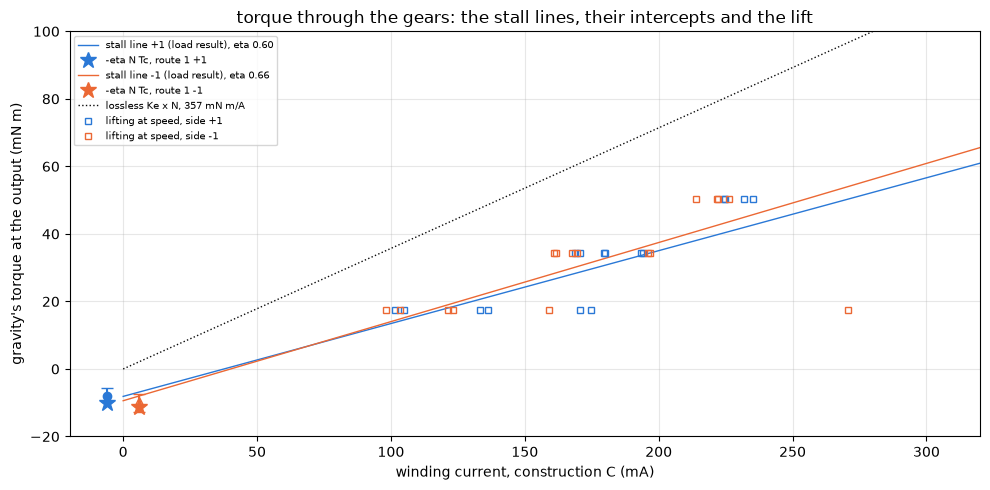

In [66]:
fig, ax = plt.subplots(figsize=(10, 5))
ii = np.linspace(0, 0.32, 10)
for s, c in (("+1", BLUE), ("-1", ORANGE)):
    k, b = KT_GEAR[s]["value"], INTERCEPT[s]["value"]
    ax.plot(ii * 1e3, b + k * ii, color=c, lw=1,
            label=f"stall line {s} (load result), eta {ETA[s]:.2f}")
    x0 = -6 if s == "+1" else 6           # the two sides apart at i = 0
    ax.errorbar(x0, b, yerr=[[b - INTERCEPT[s]["lo"]],
                             [INTERCEPT[s]["hi"] - b]], capsize=4,
                **figures.direction_style(int(s), c))
    ax.plot(x0, STALL_PRED[s][0], "*", color=c, ms=12,
            label=f"-eta N Tc, route 1 {s}")
ax.plot(ii * 1e3, ii * KEN, ":", color=INK, lw=1,
        label=f"lossless Ke x N, {KEN:.0f} mN m/A")
for side, c in ((1, BLUE), (-1, ORANGE)):
    g = LT[np.sign(LT["duty"]) == side]
    ax.plot(g["i_w_ma"], g["tau_mNm"], "s", color=c, mfc="none", ms=5,
            label=f"lifting at speed, side {side:+d}")
ax.set_xlim(-20, 320)
ax.set_ylim(-20, 100)
figures.label(ax, x="winding current, construction C (mA)",
              y="gravity's torque at the output (mN m)",
              title="torque through the gears: the stall lines, their "
              "intercepts and the lift")
ax.legend(fontsize=7)
figures.finish(fig)

What you are looking at. The load result's two stall lines, gravity's torque on the winding current, with their intercepts and brackets at zero current, the stars the intercepts route 1's Coulomb term predicts through each side's efficiency, the dotted lossless Ke x N, and the lifts at speed as open squares. The stars sit at or just past the intercepts' brackets. The lifts sit to the right of the stall lines at 10 degrees, where the free drag is a large share of the current, on them at 20 degrees and above them at 30.

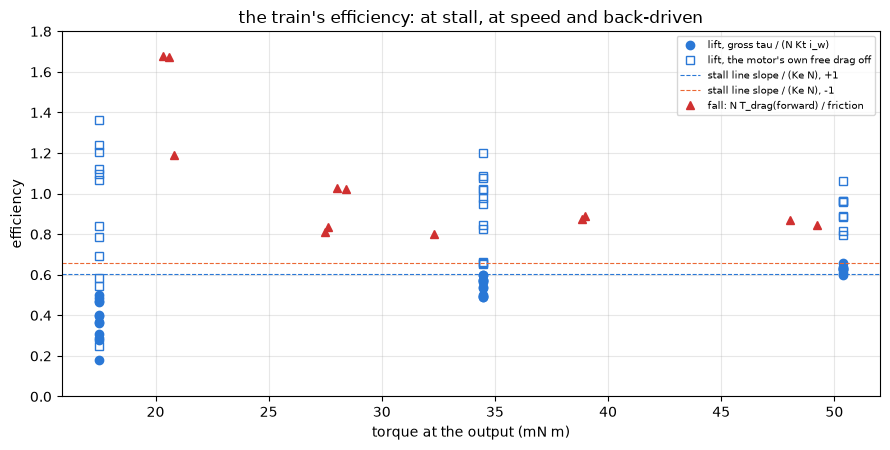

In [67]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(LT["tau_mNm"], LT["eta_gross"], "o", color=BLUE,
        label="lift, gross tau / (N Kt i_w)")
ax.plot(LT["tau_mNm"], LT["eta_mesh"], "s", color=BLUE, mfc="none",
        label="lift, the motor's own free drag off")
for s, c in (("+1", BLUE), ("-1", ORANGE)):
    ax.axhline(ETA[s], color=c, lw=0.8, ls="dashed",
               label=f"stall line slope / (Ke N), {s}")
ax.plot(FALL["tau_f_mNm"], 1 / FALL["over_r1"], "^", color=RED,
        label="fall: N T_drag(forward) / friction")
ax.set_ylim(0, 1.8)
figures.label(ax, x="torque at the output (mN m)", y="efficiency",
              title="the train's efficiency: at stall, at speed and "
              "back-driven")
ax.legend(fontsize=7)
figures.finish(fig)

What you are looking at. Efficiency against output torque, the lift's gross efficiency (circles) and with the motor's free drag off (open squares), the stall lines' slopes over Ke N per side (dashed), and the falls' N T_drag over the friction as a back-driving efficiency (triangles). The gross efficiency climbs toward the stall line's as the load grows. With the free drag off it scatters about 0.9, widest at 10 degrees, where the free drag is most of the current. The falls sit near 1 but for the -30 % pair.

## 10. What stages 5 to 7 read from here

The firmware pair is route 1's line per direction, its bracket the wider of route 1's own and route 2's line under 230 rev/s through J's bracket. Route 1's carries 2 se, the crest term's bracket, current-scale's class and Ke's bound.

In [68]:
CS_ABS = 0.02     # current-scale's absolute class, the resistance and
#                   run-up notebooks' 2 %, on every current-made torque
KE_REL = KE_HI / KE - 1                 # Ke's own bound, relative
FW = {}
for d in (1, -1):
    (tc, b), (tc_se, b_se) = CARRIED[d]["coef"], CARRIED[d]["se"]
    (tc2, b2) = LOW2[d]["coef"]
    x_g = R[(R.dir == d) & (R.tier <= 2)]["x_g_v"].mean()
    dtc_g = u_nm(KT * (G_S_HI - G_S) * x_g)   # the crest term's bracket
    dtc_sys = np.sqrt(dtc_g ** 2 + (tc * CS_ABS) ** 2 + (tc * KE_REL) ** 2)
    db_sys = np.sqrt((b * CS_ABS) ** 2 + (b * KE_REL) ** 2)
    FW[d] = {"Tc": tc, "b": b, "dtc_g": dtc_g,
             "Tc_lo": min(tc - 2 * tc_se - dtc_sys, tc2 * J_LO / J),
             "Tc_hi": max(tc + 2 * tc_se + dtc_sys, tc2 * J_HI / J),
             "b_lo": min(b - 2 * b_se - db_sys, b2 * J_LO / J),
             "b_hi": max(b + 2 * b_se + db_sys, b2 * J_HI / J)}
    f = FW[d]
    print(f"{d:+d}: Tc {tc:.1f} uN m ({f['Tc_lo']:.0f} to {f['Tc_hi']:.0f})"
          f" = {ma_at_kt(tc * 1e-6):.1f} mA; b {b:.4f} uN m s/rad "
          f"({f['b_lo']:.3f} to {f['b_hi']:.3f}) = "
          f"{ma_at_kt(b * 1e-6) * RPS:.3f} mA per rev/s; the crest term's "
          f"share {dtc_g:.1f} uN m")
print(f"systematics: current scale {CS_ABS * 100:.0f} %, Ke "
      f"{KE_REL * 100:.2f} %, J {(J_LO / J - 1) * 100:+.1f} / "
      f"{(J_HI / J - 1) * 100:+.1f} % on route 2's line")
FW["pooled"] = {"Tc": pc[0], "b": pc[1],
                **{k: min(FW[1][k], FW[-1][k]) for k in ("Tc_lo", "b_lo")},
                **{k: max(FW[1][k], FW[-1][k]) for k in ("Tc_hi", "b_hi")}}
f = FW["pooled"]
print(f"pooled: Tc {pc[0]:.1f} uN m ({f['Tc_lo']:.0f} to {f['Tc_hi']:.0f})"
      f" = {ma_at_kt(pc[0] * 1e-6):.1f} mA; b {pc[1]:.4f} "
      f"({f['b_lo']:.3f} to {f['b_hi']:.3f}) = "
      f"{ma_at_kt(pc[1] * 1e-6) * RPS:.3f} mA per rev/s; at 100 rev/s "
      f"{u_nm(drag_route1(100)):.0f} uN m "
      f"({ma_at_kt(drag_route1(100)):.0f} mA)")

+1: Tc 54.3 uN m (43 to 65) = 46.8 mA; b 0.0514 uN m s/rad (0.040 to 0.063) = 0.278 mA per rev/s; the crest term's share 1.0 uN m
-1: Tc 55.0 uN m (44 to 63) = 47.5 mA; b 0.0443 uN m s/rad (0.037 to 0.054) = 0.240 mA per rev/s; the crest term's share 1.0 uN m
systematics: current scale 2 %, Ke 0.63 %, J -8.9 / +10.0 % on route 2's line
pooled: Tc 55.1 uN m (43 to 65) = 47.5 mA; b 0.0474 (0.037 to 0.063) = 0.257 mA per rev/s; at 100 rev/s 85 uN m (73 mA)


In [69]:
DRAG_TABLE = RB[RB["rev_s"] >= 230][["dir", "rev_s", "T_uNm", "T_lo_uNm",
                                     "T_hi_uNm"]].copy()
DRAG_TABLE["ma"] = ma_at_kt(DRAG_TABLE["T_uNm"] * 1e-6)
show(DRAG_TABLE, n=None)
for at in (300, 460):
    lo = min(route2_at(d, at, RB.assign(T_uNm=RB["T_lo_uNm"]))
             for d in (1, -1))
    hi = max(route2_at(d, at, RB.assign(T_uNm=RB["T_hi_uNm"]))
             for d in (1, -1))
    mid = [route2_at(d, at) for d in (1, -1)]
    print(f"at {at} rev/s: {mid[0]:.0f} (+1) and {mid[1]:.0f} (-1) uN m, "
          f"{ma_at_kt(mid[0] * 1e-6):.0f} and {ma_at_kt(mid[1] * 1e-6):.0f}"
          f" mA; J's bracket {lo:.0f} to {hi:.0f} uN m")

,dir,rev_s,T_uNm,T_lo_uNm,T_hi_uNm,ma
9,-1,237.474,117.988,107.479,129.753,101.793
10,-1,262.117,124.904,113.779,137.359,107.759
11,-1,287.358,132.540,120.735,145.757,114.347
12,-1,312.126,138.843,126.476,152.688,119.785
13,-1,337.541,147.393,134.264,162.090,127.161
14,-1,362.483,154.697,140.918,170.123,133.463
15,-1,387.416,160.137,145.874,176.106,138.157
16,-1,412.365,162.237,147.786,178.414,139.968
17,-1,437.975,167.192,152.300,183.863,144.243
18,-1,462.339,174.186,158.671,191.555,150.277


at 300 rev/s: 139 (+1) and 136 (-1) uN m, 120 and 117 mA; J's bracket 124 to 152 uN m
at 460 rev/s: 184 (+1) and 174 (-1) uN m, 159 and 150 mA; J's bracket 158 to 202 uN m


In [70]:
FLOOR = LADDER["floor_v_effective"]
print(f"the floor: {FLOOR['value']:.3f} V effective ({FLOOR['lo']:.3f} to "
      f"{FLOOR['hi']:.3f}), the ladder result's; the slowest sustained "
      f"{w_floor:.0f} sd {SLOW['pot_rev_s'].std():.0f} rev/s at the motor "
      f"= {w_floor / GEAR * 360:.0f} deg/s at the horn, "
      f"{SLOW['i_c_ma'].mean():.0f} mA under C, "
      f"{SLOW['i_crest_ma'].mean():.0f} mA crest")
print(f"the ladder result's crawl at 0.5 V effective: "
      f"{LADDER['crawl_speed_rev_s']['value']:.1f} rev/s on "
      f"{LADDER['crawl_current_ma']['value']:.0f} mA crest; floor speed "
      f"{LADDER['floor_speed_at_lowest_turning_level_rev_s']['value']:.1f}"
      f" rev/s")
FF = (ma_at_kt(pc[0] * 1e-6), ma_at_kt(pc[1] * 1e-6) * RPS)
print(f"feed-forward in current: {FF[0]:.1f} mA plus {FF[1]:.3f} mA per "
      f"rev/s, plus the load")

the floor: 0.340 V effective (0.300 to 0.399), the ladder result's; the slowest sustained 22 sd 4 rev/s at the motor = 26 deg/s at the horn, 39 mA under C, 57 mA crest
the ladder result's crawl at 0.5 V effective: 31.8 rev/s on 66 mA crest; floor speed 19.6 rev/s
feed-forward in current: 47.5 mA plus 0.257 mA per rev/s, plus the load


- +1. Tc 54.3 uN m (43 to 65), 46.8 mA, and b 0.0514 uN m s/rad (0.040 to 0.063), 0.278 mA per rev/s.
- -1. Tc 55.0 uN m (44 to 63), 47.5 mA, and b 0.0443 uN m s/rad (0.037 to 0.054), 0.240 mA per rev/s.
- The directions do not separate (section 4), so the pooled pair is the firmware pair, Tc 55.1 uN m (43 to 65), 47.5 mA, and b 0.0474 uN m s/rad (0.037 to 0.063), 0.257 mA per rev/s, its brackets the union of the two directions'. At 100 rev/s it gives 85 uN m, 73 mA. The systematics in the brackets are the crest term's 1.0 uN m on Tc, current-scale's 2 %, Ke's 0.63 % and J's -8.9 / +10.0 % on route 2.
- Above 230 rev/s route 2's bins carry the speed range, 139 (+1) and 136 (-1) uN m, 120 and 117 mA, at 300 rev/s, J's bracket 124 to 152, and 184 and 174 uN m, 159 and 150 mA, at 460, J's bracket 158 to 202. The +1 drag stays near its line to 400 rev/s and the -1 drag flattens above 400, so each direction carries its own table there.
- The stiction. At least 49.5 to 59.6 uN m driven. Back-driven it is measured, 99 (81 to 117) uN m, 85.4 mA. The driven breakaway is not measured.
- The floor. A kicked rotor stops under 0.340 V effective (0.300 to 0.399), the same on the three rails. It does not crawl. The slowest sustained speed is 22 sd 4 rev/s at the motor, 26 deg/s at the horn, on 39 mA under C and 57 mA crest. The ladder result's crawl at 0.5 V effective runs 31.8 rev/s on 66 mA crest.
- The feed-forward. The velocity loop's current feed-forward is (Tc sgn(w) + b w) / Kt plus the load, 47.5 mA plus 0.257 mA per rev/s. Under the slowest sustained speed the open loop stops or stick-slips, so the loop, not a duty, has to carry a crawl.

### Open discrepancies

1. Route 1's Coulomb term sits above route 2's line under 230 rev/s, 54.3 against 47.0 and 55.0 against 48.2 uN m, +1.5 and +1.9 sigma, while route 1 reads 1.004 of the same sitting's coasts. The candidates are J, whose bracket covers the gap, the run-in between sittings and the crest term g at 15 to 20 % duty. One sitting with 30 % rungs and 100 % run-ups interleaved, drive and coast read within a minute of each other, plus 3.7 V run-ups at full duty for J, separates them. J predicts the same gap in every sitting, the run-in predicts it gone when the two are interleaved, and g predicts it largest at the lowest duty.
2. The 7.4 V block's coasts decelerate at 0.962 of the 5 V block's, se 0.008, and a coast carries no rail. The candidates are time, since the blocks ran in rail order, and the heat of the 7.4 V spins. Rails interleaved cycle by cycle, each coast tagged by the winding's rest resistance before it, separate them. Time predicts a trend with the cycle number, heat a trend with the resistance.
3. The low holds' running friction under C, 39.2 mA at 22.0 rev/s, sits under route 1's 52.9 mA and route 2's 42.9 mA there, and the stopped holds' C current reads 1.096 of construction C's line. At these duties g and the edge share are both extrapolated. The DC ammeter in series into a stop at 4 to 12 % duty, and holds at one effective volts on two rails, separate them. The crest term scales with (1 - D) V_on and the friction does not.
4. The settled-equivalent current is biased low on the run-up rungs over 290 rev/s, since the window before the last sits on the exponential rise and a_drive over-reads. The ladder result's settled-equivalent carries the same bias and should not feed a friction fit above 230 rev/s. The fix in the method is the drive's acceleration from a line through the window's own cycle speeds, and in the capture a longer runway for steady spins at 60 to 100 % on 3.7 V.
5. The -1 coast drag flattens above 400 rev/s, its square term -4.7 sigma, while +1 stays near its line. The candidates are a brush term, a bouncing brush that rubs harder, and an EMF tail effect at the top of the coast. The camera on a full-duty coast both ways, and the dropout rows against the deceleration residual within the +1 coasts, separate them.
6. In sitting 1 the up side's stall intercept sits 0.60 mN m outside its bracket from -eta N Tc, and Kt through the gears splits by side at 2.6 sigma, 1.6 table-only. Over three sittings the load notebook's section 11.3 does not establish the split as a ratio, and the offset by side stays open as its discrepancy 2, a train effect against a rig effect.
7. The -30 % falls read 0.60 of the forward drag at the speed peak, where the +30 % falls read 0.97 to 0.98 and the 40 % falls 1.13 to 1.18. The candidates are the pot's local scale on the down side at the peak's angle, the 40 ms smoothing on a stick-slip fall and a real side asymmetry. The same falls with the tag on the arm, and the load ladder with the sides' order swapped, separate them.
8. The lift's speed loss leaves +7.6 to +15.4 rev/s on the up side and -9.2 to +6.7 on the down side after R_C di / Ke. The brush drop's direction term is the candidate. The lift at 3.7 V separates it, since R i scales with the rail and the brush drop does not.

### The next sitting's plan

- The 30 % rungs and the full-duty run-ups interleaved in one sitting, with 3.7 V run-ups, for the gap between the routes and for J.
- The breakaway sweep, 300 ms pulses from rest at 0.3 to 1.0 V effective in 0.1 V steps, both directions, from three starts.
- The DC ammeter in series at 4 to 12 % duty, for g at low duty.
- The arm under the camera's tag, for the falls by side.

### The result file

Every quantity with its bounds and unit, motor torques in uN m and output torques in mN m.

In [71]:
q, pm = results.quantity, results.pm


def by_dir(f):
    """{"+1": f(+1), "-1": f(-1)}"""
    return {"+1": f(1), "-1": f(-1)}


def fit_of(d):
    """Route 1's carried line: one direction's, or the pooled one."""
    return POOLED if d == "pooled" else CARRIED[d]


def coef_q(d, i, unit, to=lambda x: x):
    f = fit_of(d)
    return pm(to(f["coef"][i]), to(f["se"][i]), unit)


def three(f):
    return {"+1": f(1), "-1": f(-1), "pooled": f("pooled")}


def ft(d, col):
    return FIT_TABLE[(FIT_TABLE["fit"] == "tiers 1+2")
                     & (FIT_TABLE["dir"] == d)][col].iloc[0]


def bin_q(g, col_lo, col_hi, unit, col="T_uNm"):
    return {f"{r['rev_s']:.0f} rev/s": q(r[col], r[col_lo], r[col_hi], unit)
            for _, r in g.iterrows()}

In [72]:
def to_ma(torque_unm):
    """uN m at the motor to mA at Kt."""
    return ma_at_kt(torque_unm * 1e-6)


def to_ma_rev(viscous_unm):
    """uN m s/rad to mA per rev/s at Kt."""
    return ma_at_kt(viscous_unm * 1e-6) * RPS

In [73]:
QUANTITIES = {
    "coulomb_uNm": three(lambda d: coef_q(d, 0, "uN m")),
    "viscous_uNm_s_per_rad": three(lambda d: coef_q(d, 1, "uN m s/rad")),
    "coulomb_ma_at_ke": three(lambda d: coef_q(d, 0, "mA", to_ma)),
    "viscous_ma_per_rev_s": three(lambda d: coef_q(d, 1, "mA per rev/s",
                                                   to_ma_rev)),
    "friction_fit_rms_uNm": three(lambda d: q(fit_of(d)["rms"],
                                              unit="uN m")),
    "friction_fit_rungs_used": three(lambda d: q(fit_of(d)["n"],
                                                 unit="rungs")),
    "friction_fit_speed_range_rev_s": by_dir(lambda d: q(
        FITS[("tiers 1+2", d)][1]["rev_s"].mean(), ft(d, "w_min"),
        ft(d, "w_max"), "rev/s")),
    "friction_flat_band_rev_s": by_dir(lambda d: q(
        (ft(d, "flat_lo") + ft(d, "flat_hi")) / 2, ft(d, "flat_lo"),
        ft(d, "flat_hi"), "rev/s")),
    "friction_quadratic_at_300_uNm": by_dir(lambda d: pm(
        ft(d, "c2_at_300"), ft(d, "c2_se"), "uN m")),
    "friction_quadratic_sigma": by_dir(lambda d: q(ft(d, "c2_sigma"),
                                                   unit="sigma")),
    "friction_sqrt_form_rms_uNm": by_dir(lambda d: q(ft(d, "rms_sqrt"),
                                                     unit="uN m")),
    "direction_split_sigma": {k: q(v[2], unit="sigma")
                              for k, v in SPLIT.items()},
    "direction_split_difference": {
        k: pm(v[0], v[1], "uN m" if k == "Tc" else "uN m s/rad")
        for k, v in SPLIT.items()},
    "crest_rail_slope_as_read_ma_per_v": results.line_q(
        RAIL_SLOPES["i_crest_ma"], "slope", "mA/V"),
    "crest_rail_slope_c_ma_per_v": results.line_q(
        RAIL_SLOPES["i_c_ma"], "slope", "mA/V"),
    "g_free_from_rails_ms": pm(G_FREE[0], G_FREE[1], "mS"),
    "x_c_mv_by_rung": {
        f"{r['volts_set']:g} V {r['duty_set']:.0f} % {r['dir']:+.0f}":
        q(r["X_c_mv"], unit="mV") for _, r in R[R["tier"] <= 2].iterrows()},
}
print(len(QUANTITIES), "keys")

17 keys


In [74]:
def decel_q(g):
    return {f"{r['rev_s']:.0f} rev/s": q(r["decel"], r["decel"] - r["sd"],
                                         r["decel"] + r["sd"], "rad/s^2")
            for _, r in g.iterrows()}


def coast_pair(d):
    r = FIT2_TABLE[FIT2_TABLE["dir"] == d].iloc[0]
    return {"coulomb_line": pm(r["Tc_uNm"], r["Tc_se"], "uN m"),
            "viscous_line": pm(r["b"], r["b_se"], "uN m s/rad"),
            "rms_line": q(r["rms_line"], unit="uN m"),
            "flat_band_line": q(np.mean(r["flat_line"]), *r["flat_line"],
                                "rev/s"),
            "quadratic_at_300": q(r["c2_at_300"], unit="uN m"),
            "quadratic_sigma": q(r["c2_sigma"], unit="sigma"),
            "rms_quad": q(r["rms_quad"], unit="uN m"),
            "rms_sqrt": q(r["rms_sqrt"], unit="uN m")}


QUANTITIES.update({
    "coast_decel_by_speed_rad_s2": {
        "run-up": by_dir(lambda d: decel_q(RB[RB["dir"] == d])),
        "ladder": by_dir(lambda d: decel_q(LB[LB["dir"] == d]))},
    "coast_drag_uNm_by_speed": by_dir(lambda d: bin_q(
        RB[RB["dir"] == d], "T_lo_uNm", "T_hi_uNm", "uN m")),
    "coast_pair_uNm": by_dir(coast_pair),
    "coast_pair_under_230_rev_s": by_dir(lambda d: {
        "coulomb": pm(LOW2[d]["coef"][0], LOW2[d]["se"][0], "uN m"),
        "viscous": pm(LOW2[d]["coef"][1], LOW2[d]["se"][1],
                      "uN m s/rad")}),
    "coast_early_excess_pct": {f"{iv.left:g}-{iv.right:g} ms": q(v,
                               unit="%") for iv, v in EXCESS.items()},
    "coast_rail_block_ratio": {f"{v}/5": results.mean_sd(
        RAIL_RATIO[v], "ratio") for v in (3.7, 7.4)},
    "coast_sitting_ratio": {f"{s}/1": results.mean_sd(x, "ratio")
                            for s, x in SITTING_RATIO.items()},
    "ladder_over_runup_coast_ratio": results.mean_sd(LAD_RUN["ratio"],
                                                     "ratio"),
})
print(len(QUANTITIES), "keys")

25 keys


In [75]:
QUANTITIES.update({
    "route1_over_route2": {
        "run-up coasts": results.mean_sd(M["ratio_run"], "ratio"),
        "ladder coasts": results.mean_sd(M["ratio_lad"], "ratio"),
        **{f"run-up coasts {d:+d}": results.mean_sd(
            M[M.dir == d]["ratio_run"], "ratio") for d in (1, -1)},
        **{f"ladder coasts {d:+d}": results.mean_sd(
            M[M.dir == d]["ratio_lad"], "ratio") for d in (1, -1)},
        "rungs": q(len(M), unit="rungs"),
        "diff_trend_per_100_rev_s": pm(TREND["coef"][1] * 100,
                                       TREND["se"][1] * 100, "uN m")},
    "route_pairs_sigma": by_dir(lambda d: {
        "Tc": q(PAIR_SIGMA[d][0], unit="sigma"),
        "b": q(PAIR_SIGMA[d][1], unit="sigma")}),
    "type_drag_uNm_at_speed": {m: {
        f"{w:.0f} rev/s": q(S.loc[w, m + "_drive"], unit="uN m")
        for w in W_SHARE if np.isfinite(S.loc[w, m + "_drive"])}
        for m in TYPE_NL},
    "train_share_uNm_at_speed": {
        f"{w:.0f} rev/s": q(S.loc[w, "share_uNm"], unit="uN m")
        for w in W_SHARE if np.isfinite(S.loc[w, "share_uNm"])},
    "train_share_frac_at_speed": {
        f"{w:.0f} rev/s": q(S.loc[w, "share_frac"], unit="ratio")
        for w in W_SHARE if np.isfinite(S.loc[w, "share_frac"])},
    "train_share_pair": {m: {"coulomb": q(v[0], unit="uN m"),
                             "viscous": q(v[1], unit="uN m s/rad")}
                         for m, v in SHARE_PAIRS.items()},
})
print(len(QUANTITIES), "keys")

31 keys


In [76]:
TK = TAKE_AGG
QUANTITIES.update({
    "stiction_driven_lower_uNm": {
        "c_current": q(u_nm(KT * STICK_C * 1e-3), unit="uN m (lower bound)"),
        "v_over_r": q(u_nm(KT * STICK_R * 1e-3), unit="uN m (lower bound)")},
    "stiction_driven_v_eff": q(HI_NEVER["v_eff"], HI_NEVER["v_eff"],
                               LO_ALWAYS["v_eff"], "V (stopped to turned)"),
    "floor_running_rev_s": results.mean_sd(SLOW["pot_rev_s"], "rev/s"),
    "floor_running_ma_c": results.mean_sd(SLOW["i_c_ma"], "mA"),
    "stopped_hold_c_over_line": results.mean_sd(C_RATIO, "ratio"),
    "kick_breakaway_ms": results.mean_sd(KICKS["kick_break_ms"], "ms"),
    "kick_current_ma": results.mean_sd(KICKS["kick_i_peak_ma"],
                                       "mA (upper bound)"),
    "takeup_turns": by_dir(lambda d: {
        "route1": pm(TK.loc[d, "turns_route1"], TK.loc[d, "turns_route1_sd"],
                     "turns"),
        "coulomb": q(TK.loc[d, "turns_coulomb"], unit="turns"),
        "no_drag": q(TK.loc[d, "turns_no_drag"], unit="turns")}),
    "lash_turns_quoted": {
        "motion": q(LASH_TURNS["motion"], unit="turns"),
        "hand": q(LASH_TURNS["hand"], unit="turns"),
        "steps": by_dir(lambda d: q(FREE_STEPS[
            "play_from_rest_turns_dir_" + ("pos" if d > 0 else "neg")]
            ["value"], unit="turns"))},
    "load_held_bound_uNm_motor": q(HELD_UNM, unit="uN m (lower bound)"),
    "load_release_uNm_motor": pm(REL_UNM, REL_SD_UNM, "uN m"),
    "load_static_friction_uNm_motor": q(*STATIC_BAR, "uN m"),
    "stiction_over_coulomb": {
        "driven_lower": q(RATIOS["driven_r"], RATIOS["driven_r"],
                          RATIOS["driven_c"], "ratio (lower bound)"),
        "back_driven_lower": q(RATIOS["held"], unit="ratio (lower bound)"),
        "release": q(RATIOS["release"], unit="ratio"),
        "back_driven_measured": q(*MEASURED, "ratio")},
    "arm_factor": q(SCALE, LOAD["gravity_torque_scale"]["lo"],
                    LOAD["gravity_torque_scale"]["hi"], "ratio"),
    "arm_masses_g": {k: LOAD[k] for k in ("coins_mass_g", "coin_block_g",
                                          "arm_mount_g")},
})
print(len(QUANTITIES), "keys")

46 keys


In [77]:
def eta_q(col):
    return {f"{a} deg": results.mean_sd(LT[LT.angle == a][col], "ratio")
            for a in (10, 20, 30)}


QUANTITIES.update({
    "kt_gear_mn_m_per_a_abs": KT_GEAR,
    "eta_stall": {s: q(ETA[s], KT_GEAR[s]["lo"] / KEN,
                       KT_GEAR[s]["hi"] / KEN, "ratio")
                  for s in ("+1", "-1", "pooled")},
    "stall_intercept_mn_m": {s: INTERCEPT[s] for s in ("+1", "-1")},
    "eta_n_tc_pred_mn_m": {s: q(STALL_PRED[s][0], unit="mN m")
                           for s in ("+1", "-1")},
    "stall_i0_ma": {s: q(STALL_PRED[s][1], unit="mA") for s in ("+1", "-1")},
    "stall_torque_horn_mn_m": q(HORN, unit="mN m"),
    "eta_lift_gross_by_angle": eta_q("eta_gross"),
    "eta_lift_mesh_by_angle": eta_q("eta_mesh"),
    "lift_loss_share_r_di_ke": {
        f"{a} deg": results.mean_sd((LT.dw_r / LT.dw)[LT.angle == a],
                                    "ratio") for a in (10, 20, 30)},
    "lift_loss_rest_mv_by_side": {
        f"{s:+d}": results.median_range(
            LT[np.sign(LT["duty"]) == s]["rest_mv"], "mV")
        for s in (1, -1)},
    "fall_over_forward_drag": {
        "route1": results.mean_sd(FAST["over_r1"], "ratio"),
        "route2": results.mean_sd(FAST["over_r2"], "ratio"),
        **{f"{lift:+d} %": results.median_range(g["over_r1"], "ratio")
           for lift, g in FALL.groupby("lift")}},
    "fall_pair_motor_uNm": {
        "coulomb": q(FALL_TC["value"] / GEAR * 1e3,
                     FALL_TC["lo"] / GEAR * 1e3, FALL_TC["hi"] / GEAR * 1e3,
                     "uN m"),
        "viscous": q(FALL_B["value"] / GEAR ** 2 * 1e3,
                     FALL_B["lo"] / GEAR ** 2 * 1e3,
                     FALL_B["hi"] / GEAR ** 2 * 1e3, "uN m s/rad")},
    "fall_emf_over_pot": FALL_EMF,
})
print(len(QUANTITIES), "keys")

59 keys


In [78]:
def fw_q(d):
    f = FW[d]
    return {"coulomb_uNm": q(f["Tc"], f["Tc_lo"], f["Tc_hi"], "uN m"),
            "viscous_uNm_s_per_rad": q(f["b"], f["b_lo"], f["b_hi"],
                                       "uN m s/rad"),
            "coulomb_ma": q(*(ma_at_kt(x * 1e-6) for x in
                              (f["Tc"], f["Tc_lo"], f["Tc_hi"])), "mA"),
            "viscous_ma_per_rev_s": q(*(ma_at_kt(x * 1e-6) * RPS for x in
                                        (f["b"], f["b_lo"], f["b_hi"])),
                                      "mA per rev/s")}


QUANTITIES.update({
    "firmware_pair": {"+1": fw_q(1), "-1": fw_q(-1),
                      "pooled": fw_q("pooled")},
    "drag_table_uNm_by_speed": by_dir(lambda d: bin_q(
        DRAG_TABLE[DRAG_TABLE["dir"] == d], "T_lo_uNm", "T_hi_uNm",
        "uN m")),
    "floor_v_effective_quoted": FLOOR,
    "floor_speed_rev_s": results.mean_sd(SLOW["pot_rev_s"], "rev/s"),
    "crawl_feed_forward_ma": {"coulomb": q(FF[0], unit="mA"),
                              "per_rev_s": q(FF[1], unit="mA per rev/s")},
    "ke_used": q(KE, unit="V s/rad"), "r_c_used": q(R_C, unit="ohm"),
    "v0_c_used": q(V0_C, unit="V"), "g_used": q(G_S * 1e3, unit="mS"),
    "j_used": q(J, J_LO, J_HI, "kg m^2"),
    "edge_ticks_used_by_rail": {
        f"{v} V": q(SC.edge_lags_at(v)[0] - SC.edge_lags_at(v)[1],
                    unit="ticks") for v in (3.7, 5.0, 7.4)},
})
print(len(QUANTITIES), "keys")

70 keys


The notes that define every key.

In [79]:
NOTES = (
    "stage 3 friction of mg90-d on dev-v006-2A-D, no capture of its own: "
    "ladder/capture-1, ladder/rail-1 and ladder/low-1 (sitting servo-1), "
    "the six run-up sets, steps/capture-1 and load/lift-1 re-read from raw, "
    "the rest from the results named. Torques at the motor in uN m (mA at "
    "Ke = Kt), w in rad/s, output torques in mN m. Route 1: each spin's "
    "held duty's last 100 ms (at most half the held rows, at least 20 ms), "
    "crest current over the sweep's torque-off zero with stage 1's in-drive "
    "offset out, the ripple tach seeded by the coast's EMF line and vetted "
    "by the pot, construction C at the probe's rail (stage 1's edge lags on "
    "the rail, the brake loop, g the resistance result's meter_g_ms off the "
    "current), the J-free settled-equivalent i / (1 + a_drive / a_coast); "
    "rung means; tier 1 settle within 2.5 %, tier 2 within 7 %, fits over "
    "tiers 1 and 2, T = Tc + b w by least squares, se bounds; flat band the "
    "widest run of 75 rev/s bins whose mean residual sits within 2 se or "
    "half the rms. x_c_mv_by_rung the volts balance v_c - R_C i_c - V0_C - "
    "Ke w. Route 2: coast EMF from the cut, open rows bridged, quadratics "
    "every 0.5 ms over +/-5 ms (oscnb.coast), 25 rev/s bins with 5 fits or "
    "more, the median deceleration +/- sd, torque J x it with J's bracket "
    "as lo and hi; lines weighted by the bin se. route1_over_route2 the "
    "steady rungs over route 2 interpolated at their speed. "
)

In [80]:
NOTES += (
    "Train share: route 2's mean of directions less the mean of mg90-b's "
    "and mg90-c's 5 V meter drive drag (stage 2 no-load-current), a type "
    "comparison; mg90-d's motor never ran bare. Low holds: the hold's last "
    "400 ms, turning when the pot and the coast's early EMF both read over "
    "1 rev/s; stiction_driven_lower the highest level that never "
    "restarted, its C current and (V_c - V0_C) / R_C, lower bounds. "
    "takeup_turns the current through J with the drag named off until the "
    "pot moves 3 counts from its 1 to 2 ms reference, steps 20 % starts. "
    "Load bounds from the load result, divided by N with no loss. Stall "
    "lines, Kt through the gears and intercepts the load result's; eta "
    "over Ke N; the prediction -eta N Tc with route 1's Tc per direction. "
    "Lift rows recomputed the load notebook's way (pot slope over +/-12.5 "
    "ms, +/-2 deg windows past 30 ms, construction C at 5 V), against "
    "route 1's 5 V rungs; falls' friction gravity at the 40 ms "
    "Savitzky-Golay speed peak, over N times the forward drag at that "
    "motor speed. firmware_pair: route 1 with bounds the wider of 2 se plus "
    "the crest term's bracket, current-scale's 2 % and Ke's bound, and "
    "route 2's line under 230 rev/s through J's bracket; the pooled bounds "
    "the union of the directions'. drag_table route 2 above 230 rev/s. "
    "One servo, its train in fresh Super Lube still running in. "
    "load_static_friction_uNm_motor the load result's measured static "
    "friction of sittings 2 and 3, back_driven_measured it over route 1's "
    "pooled Tc."
)

In [81]:
CAPTURES = [PAIR_DIR / "ladder", PAIR_DIR / "run-up",
            PAIR_DIR / "steps" / "capture-1", LIFT_DIR]
path = results.write("3-servo", "friction", PAIR_DIR,
                     pair=PAIR, notes=NOTES, **QUANTITIES)
written = results.read("3-servo", "friction", pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])
print("read:", ", ".join(str(results.rel(c)) for c in CAPTURES))
flat = [{"key": k, **v} for k, v in written.items()
        if isinstance(v, dict) and "value" in v]
show(pd.DataFrame(flat), n=None)

wrote stages/3-servo/friction/results/mg90-d__dev-v006-2A-D.json with 70 keys, capture telemetry/mg90-d__dev-v006-2A-D
read: telemetry/mg90-d__dev-v006-2A-D/ladder, telemetry/mg90-d__dev-v006-2A-D/run-up, telemetry/mg90-d__dev-v006-2A-D/steps/capture-1, telemetry/mg90-d__dev-v006-2A-D/load/lift-1


,key,value,lo,hi,unit
0,crest_rail_slope_as_read_ma_per_v,4.455,3.667,5.242,mA/V
1,crest_rail_slope_c_ma_per_v,-0.269,-1.067,0.529,mA/V
2,g_free_from_rails_ms,4.644,3.897,5.391,mS
3,ladder_over_runup_coast_ratio,1.026,0.989,1.063,ratio
4,stiction_driven_v_eff,0.300,0.300,0.399,V (stopped to turned)
5,floor_running_rev_s,21.993,17.670,26.316,rev/s
6,floor_running_ma_c,39.165,34.399,43.932,mA
7,stopped_hold_c_over_line,1.096,1.013,1.179,ratio
8,kick_breakaway_ms,9.181,7.299,11.064,ms
9,kick_current_ma,311.136,287.271,335.001,mA (upper bound)


## Conclusion

At the motor the servo's drag is a Coulomb term and a viscous term, Tc 55.1 uN m and b 0.0474 uN m s/rad pooled, 47.5 mA and 0.257 mA per rev/s at Ke, from the ladder's steady rungs between 57 and 223 rev/s. The two directions do not separate. The free coasts read the same drag with no electrical term, route 1 at 1.004 of the same sitting's coasts, and above 230 rev/s they carry the table to 460 rev/s, where the -1 drag flattens. The rails fall on one curve once the crest term comes off the current, and the friction read gives g as 4.64 +/- 0.75 mS from a third dataset. Against the type's bare motors the train adds a share that grows with speed, 0.262 to 0.424 of the servo's drag.

Back-driven from the output the stiction is measured, 99 (81 to 117) uN m at the motor, 1.47 to 2.12 times the running Coulomb term. Driven from the motor it is bounded, at least about the running Coulomb term, and the driven breakaway is not measured. A duty hold under the arm is a ratchet, with a deadband of 5 to 10 % of duty up and 20 to 25 % down. Through the gears the train passes 0.624 of the lossless torque at a rising stall in sitting 1 and 0.632 (0.620 to 0.678) over the load result's three sittings, one value for both directions with the side split not established, and 0.90 to 0.92 of the torque above its free drag while lifting, and it back-drives at about the cost of free running.